# **Experiment Notebook**



In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.3'

---
## Student Information

In [4]:
# <Student to fill this section>
student_name = "Parisasadat Kalaki"
student_id = "25969686"

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [6]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

---
## 0. Python Packages

In [ ]:
# ------------------------------------------------------------
# 0. Python Packages
# ------------------------------------------------------------

# Core data handling
# pandas is used for working with tabular weather data.
# numpy is used for numerical calculations, including
# the mathematical formulas required to calculate CCI.
import pandas as pd
import numpy as np


# File and path management
# Path allows us to create file paths that work consistently
# across different operating systems.
from pathlib import Path


# Data collection
# requests is used to send HTTP requests to the Open-Meteo
# Historical Weather API and retrieve historical weather data.
import requests
from joblib import dump

# Data visualisation
# matplotlib is used to create plots and charts.
# seaborn provides additional statistical visualisation tools.
import matplotlib.pyplot as plt
import seaborn as sns


# Machine learning pipeline and preprocessing
# Pipeline allows preprocessing and modelling steps to be
# combined into a single reproducible workflow.
#
# StandardScaler standardises numerical features. It is
# particularly useful for linear models such as Ridge Regression.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# Regression model
# Ridge Regression is used as a regularised linear regression
# baseline for predicting the Climate Comfort Index (CCI).
from sklearn.linear_model import Ridge


# Model evaluation metrics
# These metrics are used to evaluate the performance of the
# CCI regression model.
#
# MAE  = Mean Absolute Error
# MSE  = Mean Squared Error
# R2   = R-squared
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# Model persistence
# joblib allows trained machine learning models to be saved
# to disk and loaded later by the FastAPI application.
import joblib


# Reproducibility
# A fixed random state ensures that experiments involving
# randomness can be reproduced consistently.
RANDOM_STATE = 42

# ------------------------------------------------------------
# Custom AT2 Package
# ------------------------------------------------------------

# Import reusable exploratory data-analysis functions
# from the custom Python package published for this assignment.
from ml_utils.exploration import (
    explore_distribution,
    explore_feature_vs_target,
    explore_feature_vs_categorical_target,
    explore_categorical_distribution,
)

# Import the reusable feature-engineering transformation
# from the custom package.
from ml_utils.transformations import (
    add_log_transforms,
)
from ml_utils.evaluation import evaluate_regression


---
## A. Project Description


In [8]:
business_use_case_description = """
This project develops a Climate Comfort Index (CCI) forecasting service
for Sydney, NSW, Australia, using historical weather observations from
the Open-Meteo Historical Weather API. The CCI combines temperature,
relative humidity, wind speed, cloud cover, and precipitation into a
single interpretable score ranging from 0 to 100, where higher values
indicate more suitable conditions for outdoor activities.

The machine learning objective is to forecast CCI at three separate
horizons: 1 day, 2 days, and 3 days ahead, using information that would
have been available at the prediction date. The resulting predictions
will be exposed through a FastAPI REST service.

The service is intended to support downstream applications such as
outdoor event planning, tourism, recreation, activity planning, and
consumer weather applications by converting multiple weather variables
into a single decision-support indicator.
"""

In [9]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [10]:
business_objectives = """
The primary business objective is to provide useful CCI forecasts for
1, 2, and 3 days ahead in Sydney. These forecasts can help stakeholders
make better-informed decisions about outdoor activities by identifying
periods expected to have more or less comfortable conditions.

Prediction errors may have different practical consequences depending on
their magnitude and the underlying weather conditions. Small errors
between similar comfort levels are likely to have limited practical
impact, whereas larger errors during genuinely poor or unusual weather
could result in inappropriate planning decisions.

Therefore, model evaluation considers overall predictive accuracy and
model behaviour under less typical weather conditions. The model is
intended as a decision-support tool rather than the sole basis for
high-stakes decisions.
"""

In [11]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [12]:
stakeholders_expectations_explanations = """
The prediction service will be consumed through the
/predict/index/comfort_climate API endpoint. Primary stakeholders include
downstream application developers, outdoor event planners, tourism
operators, activity-planning services, and operators of consumer weather
applications.

These stakeholders are expected to use the 1-, 2-, and 3-day CCI
forecasts as interpretable decision-support measures rather than as a
replacement for detailed weather information. The service should provide
consistent and understandable predictions, clearly identify prediction
dates, and handle invalid input dates appropriately.

Model limitations should also be communicated clearly, particularly
because unusual weather conditions may be less common in the historical
training data and therefore more difficult to predict accurately. The
historical modelling period is restricted to 2010-2025, while observations
from 2026 onwards are treated as production-period data and must not be
used during model development.
"""

In [13]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

In [14]:
hypothesis_explanations = """
H1: Ridge Regression models trained on daily-aggregated Sydney weather
features can predict the 1-day, 2-day, and 3-day-ahead Climate Comfort
Index with lower Mean Absolute Error (MAE) than corresponding
DummyRegressor baselines.

This is expected because CCI is a structured, formula-derived target
based on multiple weather conditions. CCI-informed feature engineering
and Ridge regularisation should allow the models to capture useful
relationships while reducing the influence of correlated predictors.
"""

In [15]:
print_tile(size="h3", key='hypothesis_explanations', value=hypothesis_explanations)

---
## C. Data Understanding

### C.1   Load Raw Data


In [16]:
# ------------------------------------------------------------
# C.1 Load Raw Data
# ------------------------------------------------------------

def fetch_sydney_weather(start_date: str, end_date: str) -> pd.DataFrame:
    """
    Fetch hourly historical weather data for Sydney from Open-Meteo.

    Only data before 2026-01-01 is allowed for model development.
    """

    # Convert dates to pandas timestamps for validation.
    start = pd.Timestamp(start_date)
    end = pd.Timestamp(end_date)
    cutoff = pd.Timestamp("2026-01-01")

    # Prevent accidental use of production-period data.
    if start >= cutoff:
        raise ValueError("start_date must be before 2026-01-01")

    if end >= cutoff:
        raise ValueError("end_date must be before 2026-01-01")

    # Check that the date range is valid.
    if start > end:
        raise ValueError("start_date must be earlier than end_date")

    # Open-Meteo Historical Weather API.
    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": -33.8688,
        "longitude": 151.2093,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": [
            "temperature_2m",
            "relative_humidity_2m",
            "wind_speed_10m",
            "wind_gusts_10m",
            "cloud_cover",
            "precipitation",
            "snowfall",
        ],
        "timezone": "Australia/Sydney",
    }

    # Send request to Open-Meteo.
    response = requests.get(url, params=params, timeout=30)

    # Raise an error if the request failed.
    response.raise_for_status()

    # Convert API response to a Python dictionary.
    data = response.json()

    # Convert hourly data into a DataFrame.
    df = pd.DataFrame(data["hourly"])

    # Convert time to pandas datetime.
    df["time"] = pd.to_datetime(df["time"])

    return df


# Load historical data from 2010 to 2025.
# 2026+ data must not be used during experimentation.
raw = fetch_sydney_weather(
    "2010-01-01",
    "2025-12-31"
)

# Display dataset dimensions.
print("Raw dataset shape:", raw.shape)

Raw dataset shape: (140256, 8)


In [17]:
raw.head()

,time,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_gusts_10m,cloud_cover,precipitation,snowfall
0,2010-01-01 00:00:00,21.1,95,7.4,13.7,58,0.0,0.0
1,2010-01-01 01:00:00,21.0,96,5.6,10.1,87,0.0,0.0
2,2010-01-01 02:00:00,20.9,96,4.4,9.7,87,0.0,0.0
3,2010-01-01 03:00:00,20.8,97,4.1,8.6,82,0.0,0.0
4,2010-01-01 04:00:00,20.8,97,4.4,8.6,100,0.0,0.0


In [18]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140256 entries, 0 to 140255
Data columns (total 8 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   time                  140256 non-null  datetime64[ns]
 1   temperature_2m        140256 non-null  float64       
 2   relative_humidity_2m  140256 non-null  int64         
 3   wind_speed_10m        140256 non-null  float64       
 4   wind_gusts_10m        140256 non-null  float64       
 5   cloud_cover           140256 non-null  int64         
 6   precipitation         140256 non-null  float64       
 7   snowfall              140256 non-null  float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 8.6 MB


In [19]:
raw.isna().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
wind_gusts_10m          0
cloud_cover             0
precipitation           0
snowfall                0
dtype: int64

In [20]:
raw["time"].min(), raw["time"].max()

(Timestamp('2010-01-01 00:00:00'), Timestamp('2025-12-31 23:00:00'))

In [21]:
raw.duplicated(subset="time").sum()

np.int64(0)

### C.2 Define Target variable


The target variable for this notebook is the Climate Comfort Index (CCI).

CCI is a continuous regression target ranging from 0 to 100.

The index measures how suitable daily weather conditions are for
outdoor human activities, where higher values indicate more comfortable
conditions.

CCI is calculated from five daily weather variables:
- Mean temperature
- Mean relative humidity
- Mean wind speed
- Mean cloud cover
- Total precipitation

Each variable is converted into a component score between 0 and 1.
The component scores are then combined using the fixed weights
specified in the assignment brief.

For the prediction service, CCI will be forecast at three daily
horizons: 1 day ahead, 2 days ahead, and 3 days ahead.

In [22]:
target_definition_explanations = """
The target variable for this notebook is the Climate Comfort Index (CCI),
a continuous regression target ranging from 0 to 100 that measures how
suitable a day's weather conditions are for outdoor human activities.
Higher CCI values indicate more comfortable conditions.

The CCI is calculated from five daily-aggregated weather variables:
mean temperature, mean relative humidity, mean wind speed, mean cloud
cover, and total precipitation.

Each weather variable is converted into a component score between 0 and 1.
The component scores are then combined using fixed weights: temperature
(0.35), humidity (0.20), wind speed (0.15), cloud cover (0.15), and
precipitation (0.15). The resulting weighted score is multiplied by 100
to produce the final CCI.

The machine learning task is to forecast the CCI three days ahead using
weather information that would have been available at the prediction
date. This makes CCI a continuous regression problem rather than a
classification problem.

From a business perspective, CCI provides a single interpretable measure
that downstream consumers of the Weather Intelligence API, such as
tourism operators, outdoor event planners, and activity-planning
applications, can use to assess expected outdoor comfort without having
to interpret multiple weather variables individually.
"""

In [23]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [24]:
# ------------------------------------------------------------
# C.3 Create Target Variable
# ------------------------------------------------------------

# Extract the calendar date from the hourly timestamp.
# The assignment requires daily-granularity CCI.
raw["date"] = raw["time"].dt.date


# Aggregate hourly weather observations into daily values.
#
# Mean is used for:
# - temperature
# - relative humidity
# - wind speed
# - cloud cover
#
# Sum is used for:
# - precipitation
#
# This follows the aggregation requirements in the assignment brief.
daily = (
    raw.groupby("date")
    .agg(
        temperature_2m=("temperature_2m", "mean"),
        relative_humidity_2m=("relative_humidity_2m", "mean"),
        wind_speed_10m=("wind_speed_10m", "mean"),
        cloud_cover=("cloud_cover", "mean"),
        precipitation=("precipitation", "sum"),
    )
    .reset_index()
)


# Convert the date column back to pandas datetime format.
daily["date"] = pd.to_datetime(daily["date"])

In [25]:

# ------------------------------------------------------------
# Calculate the Climate Comfort Index
# ------------------------------------------------------------

def compute_cci(df: pd.DataFrame) -> pd.DataFrame:
    """
    Calculate the Climate Comfort Index (CCI) from
    daily-aggregated weather observations.
    """

    df = df.copy()

    # Temperature score:
    # Maximum comfort occurs at 22°C.
    temp_score = np.maximum(
        0,
        1 - np.abs(df["temperature_2m"] - 22) / 20
    )

    # Humidity score:
    # Maximum comfort occurs at 50% relative humidity.
    humidity_score = np.maximum(
        0,
        1 - np.abs(df["relative_humidity_2m"] - 50) / 50
    )

    # Wind score:
    # Maximum comfort occurs at 10 km/h.
    wind_score = np.maximum(
        0,
        1 - np.abs(df["wind_speed_10m"] - 10) / 40
    )

    # Cloud-cover score:
    # Lower cloud cover produces a higher score.
    cloud_score = np.maximum(
        0,
        1 - df["cloud_cover"] / 100
    )

    # Rain score:
    # Higher precipitation produces a lower score.
    rain_score = np.maximum(
        0,
        1 - df["precipitation"] / 20
    )

    # Combine the five component scores using
    # the fixed weights from the assignment.
    df["cci"] = 100 * (
        0.35 * temp_score
        + 0.20 * humidity_score
        + 0.15 * wind_score
        + 0.15 * cloud_score
        + 0.15 * rain_score
    )

    return df


# Calculate daily CCI.
daily = compute_cci(daily)


In [26]:
# ------------------------------------------------------------
# Create CCI Forecasting Targets
# ------------------------------------------------------------

# Create separate forecasting targets for each required horizon.
#
# shift(-1): today's features -> CCI tomorrow
# shift(-2): today's features -> CCI in two days
# shift(-3): today's features -> CCI in three days
#
# These are three different prediction problems and will later
# be fitted using three separate Ridge models.

daily["cci_target_1d"] = daily["cci"].shift(-1)
daily["cci_target_2d"] = daily["cci"].shift(-2)
daily["cci_target_3d"] = daily["cci"].shift(-3)


# Display the targets to verify the alignment.
daily[
    [
        "date",
        "cci",
        "cci_target_1d",
        "cci_target_2d",
        "cci_target_3d",
    ]
].head()

,date,cci,cci_target_1d,cci_target_2d,cci_target_3d
0,2010-01-01,68.320312,67.201042,69.328125,77.850521
1,2010-01-02,67.201042,69.328125,77.850521,86.596354
2,2010-01-03,69.328125,77.850521,86.596354,82.784375
3,2010-01-04,77.850521,86.596354,82.784375,75.725000
4,2010-01-05,86.596354,82.784375,75.725000,80.909896


### C.4 Explore Target variable

count    5843.000000
mean       71.821012
std        10.281127
min        28.634375
25%        66.207031
50%        72.944792
75%        78.678646
max        98.889583
Name: cci_target_1d, dtype: float64


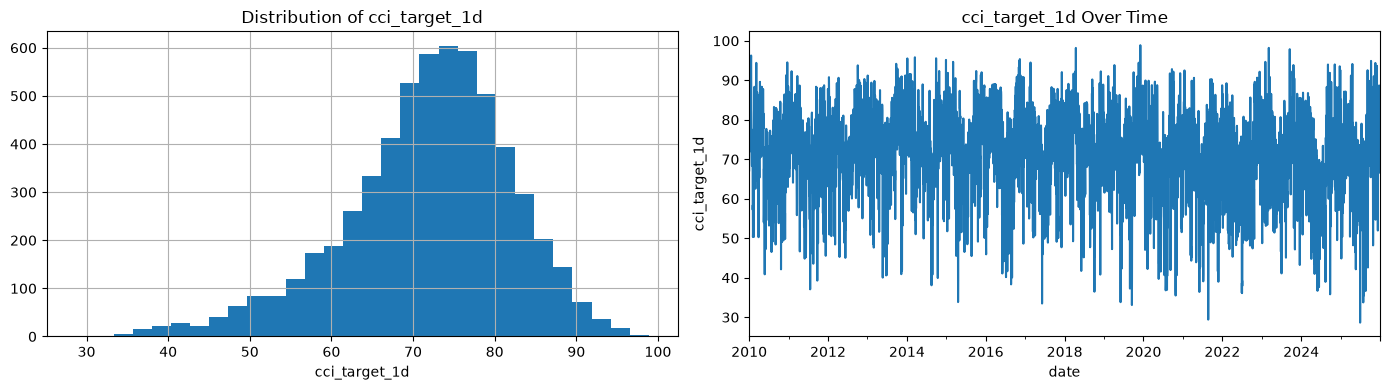

count    5842.000000
mean       71.821802
std        10.281829
min        28.634375
25%        66.204557
50%        72.947917
75%        78.680990
max        98.889583
Name: cci_target_2d, dtype: float64


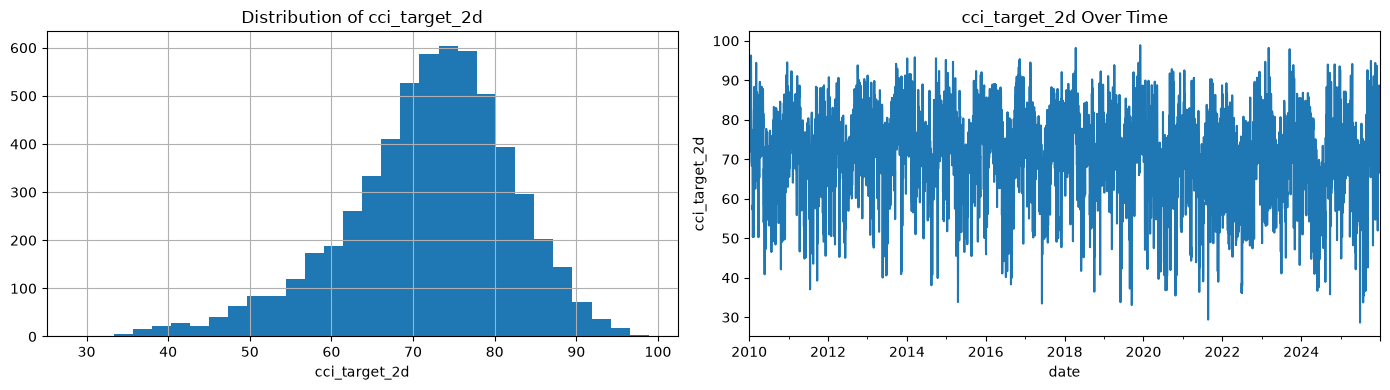

count    5841.000000
mean       71.822229
std        10.282658
min        28.634375
25%        66.202083
50%        72.951042
75%        78.683333
max        98.889583
Name: cci_target_3d, dtype: float64


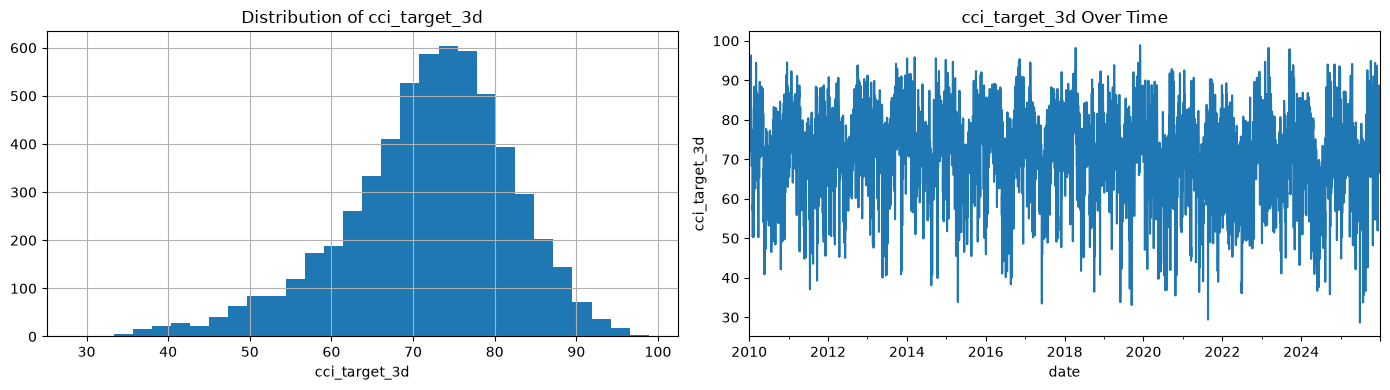

Missing target values:
cci_target_1d    1
cci_target_2d    2
cci_target_3d    3
dtype: int64


In [27]:
# ------------------------------------------------------------
# C.4 Explore Target Variable
# ------------------------------------------------------------

# Examine the distributions of the three CCI forecasting targets.
# The final rows are expected to contain NaN values because future
# CCI values are unavailable beyond the end of the historical dataset.

explore_distribution(daily, "cci_target_1d")
explore_distribution(daily, "cci_target_2d")
explore_distribution(daily, "cci_target_3d")


# Count missing target values created by the forecasting shifts.
#
# Expected:
# - 1-day target: 1 missing value
# - 2-day target: 2 missing values
# - 3-day target: 3 missing values

target_columns = [
    "cci_target_1d",
    "cci_target_2d",
    "cci_target_3d",
]

print("Missing target values:")
print(daily[target_columns].isna().sum())

In [28]:
daily["cci_target_3d"].isna().sum()

np.int64(3)

In [29]:
# ------------------------------------------------------------
# C.4 Target Distribution Interpretation
# ------------------------------------------------------------

target_distribution_explanations = """
The three CCI forecasting targets have very similar distributions. Their
means are approximately 71.8, with medians between 72.9 and 73.0. Across
the targets, CCI values range from approximately 28.6 to 98.9, indicating
that most days experienced relatively comfortable conditions.

Most observations fall within the Comfortable (60-79) and Excellent
(80-100) ranges defined in the assignment brief. A smaller number of
observations fall within the Moderate (40-59) and Poor (20-39) ranges.
No observations fall within the Very Poor (0-19) range.

Lower-CCI observations are important for evaluation because they represent
less common weather conditions. Model performance should therefore be
examined across different CCI levels, rather than relying only on overall
regression metrics.

The forward shifts created one, two, and three missing values for the
1-day, 2-day, and 3-day targets respectively. These missing values occur
at the end of the dataset because the required future CCI values are not
available. The affected rows will be excluded during model preparation.

Because CCI is a continuous regression target, class imbalance is not
directly applicable. However, the target distribution should still be
considered when interpreting errors for less frequent low-CCI conditions.

CCI is a formula-derived proxy rather than a direct measurement of
subjective human comfort. Its values depend on the specified component
weights, reference values, and scoring thresholds.
"""

In [30]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `temperature_2m`

count    5844.000000
mean       17.558109
std         4.225572
min         7.625000
25%        13.929167
50%        17.666667
75%        20.942708
max        30.904167
Name: temperature_2m, dtype: float64


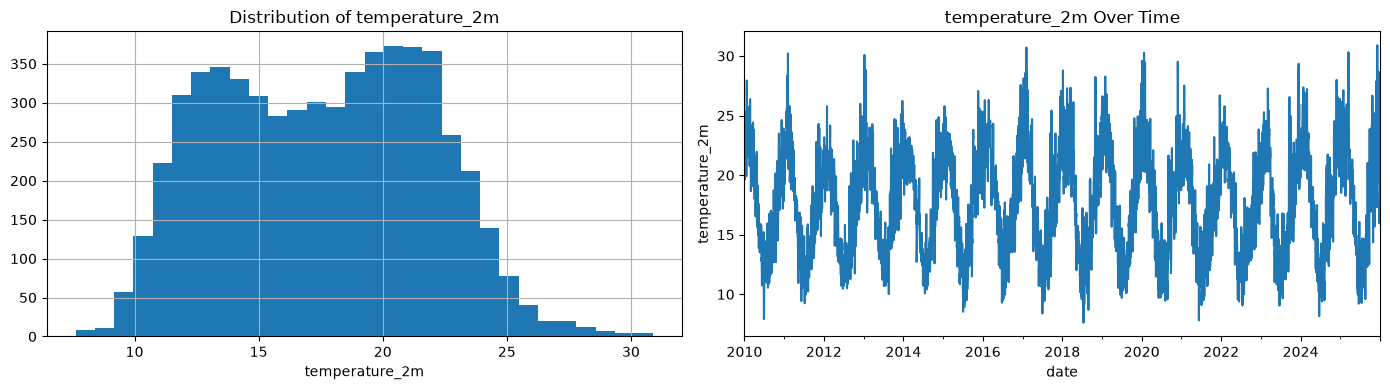

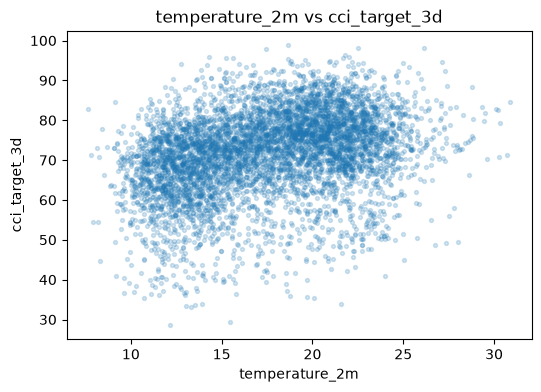

                temperature_2m  cci_target_3d
temperature_2m        1.000000       0.310644
cci_target_3d         0.310644       1.000000


In [31]:
# ------------------------------------------------------------
# C.5 Explore Feature of Interest: Temperature
# ------------------------------------------------------------

# Use the reusable exploratory functions from the custom
# AT1 package published for this assignment.
from ml_utils.exploration import (
    explore_distribution,
    explore_feature_vs_target,
)


# Explore the distribution of daily mean temperature.
explore_distribution(daily, "temperature_2m")


# Examine the relationship between daily mean temperature
# and the 3-day-ahead CCI target.
explore_feature_vs_target(
    daily,
    "temperature_2m",
    "cci_target_3d"
)

In [32]:
feature_1_insights = """
Daily mean temperature ranges from 7.6°C to 30.9°C, with a mean of
17.6°C and a median of 17.7°C. Its correlation with the 3-day-ahead CCI
target is 0.31, indicating a weak-to-moderate positive association.

However, CCI is highest near the optimal temperature of 22°C, meaning
the relationship is not strictly linear and temperatures above or below
this value can reduce comfort. Therefore, temperature deviation from
22°C was considered as an engineered feature to better represent its
relationship with CCI.
"""

In [33]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.7 Explore Feature of Interest `relative_humidity_2m`

count    5844.000000
mean       72.579127
std        11.000282
min        23.875000
25%        66.125000
50%        74.250000
75%        80.760417
max        96.041667
Name: relative_humidity_2m, dtype: float64


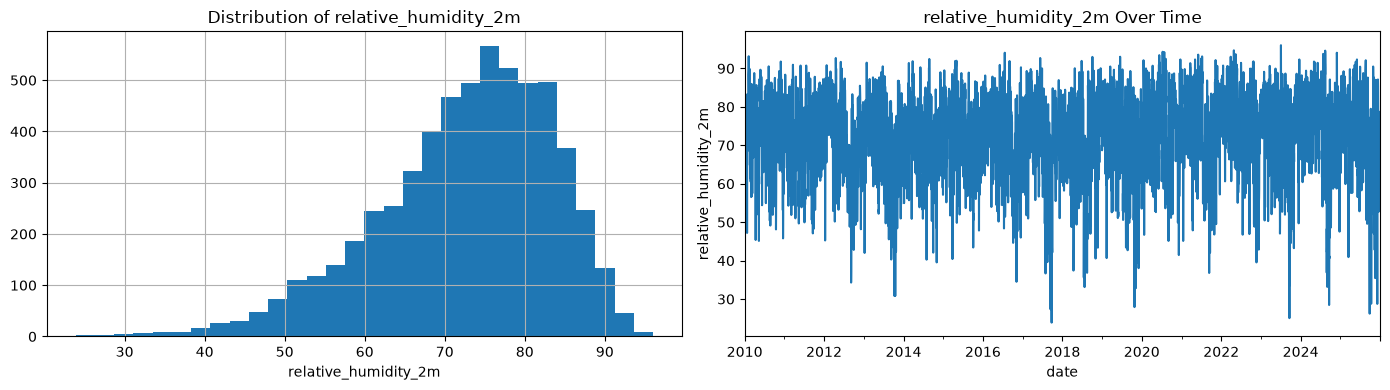

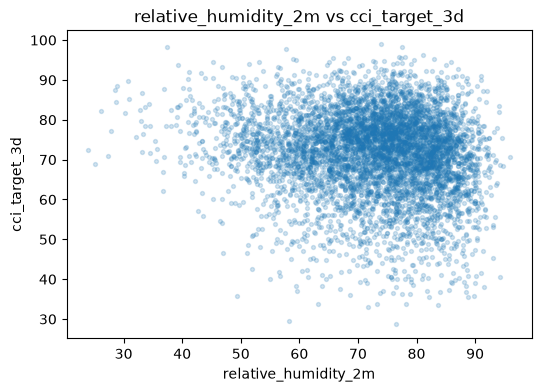

                      relative_humidity_2m  cci_target_3d
relative_humidity_2m              1.000000      -0.131653
cci_target_3d                    -0.131653       1.000000


In [34]:
# ------------------------------------------------------------
# C.7 Explore Feature of Interest: Relative Humidity
# ------------------------------------------------------------

# Explore the distribution of daily mean relative humidity.
explore_distribution(
    daily,
    "relative_humidity_2m"
)

# Examine the relationship between daily mean relative humidity
# and the 3-day-ahead CCI target.
explore_feature_vs_target(
    daily,
    "relative_humidity_2m",
    "cci_target_3d"
)

In [35]:
feature_2_insights = """
Daily mean relative humidity ranges from approximately 23.9% to 96.0%,
with a mean of 72.6% and a median of 74.3%. The distribution indicates
that Sydney's daily humidity is generally above the 50% reference value
used in the CCI formula.

The Pearson correlation between daily mean relative humidity and the
3-day-ahead CCI target is approximately -0.13, indicating a weak negative
linear association. This suggests that higher humidity tends to be
associated with slightly lower future CCI values, although the linear
relationship is weak.

The weak correlation is consistent with the structure of the CCI
HumidityScore, which is based on the absolute distance from the ideal
humidity level of 50%. Humidity values both below and above 50% can
reduce the comfort score, meaning a simple linear correlation cannot
fully capture the underlying relationship.

Because the historical mean humidity is substantially above the 50%
reference point, many observations occur on the higher-humidity side of
the CCI scoring function. An engineered feature representing the
absolute deviation from 50% may therefore provide a more direct
representation of humidity's relationship with CCI, particularly for
linear models.

Relative humidity will be retained for subsequent feature engineering
and model experiments.
"""

In [36]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.8 Explore Feature of Interest `wind_speed_10m`


count    5844.000000
mean       11.944032
std         4.586922
min         3.408333
25%         8.553125
50%        11.018750
75%        14.483333
max        37.387500
Name: wind_speed_10m, dtype: float64


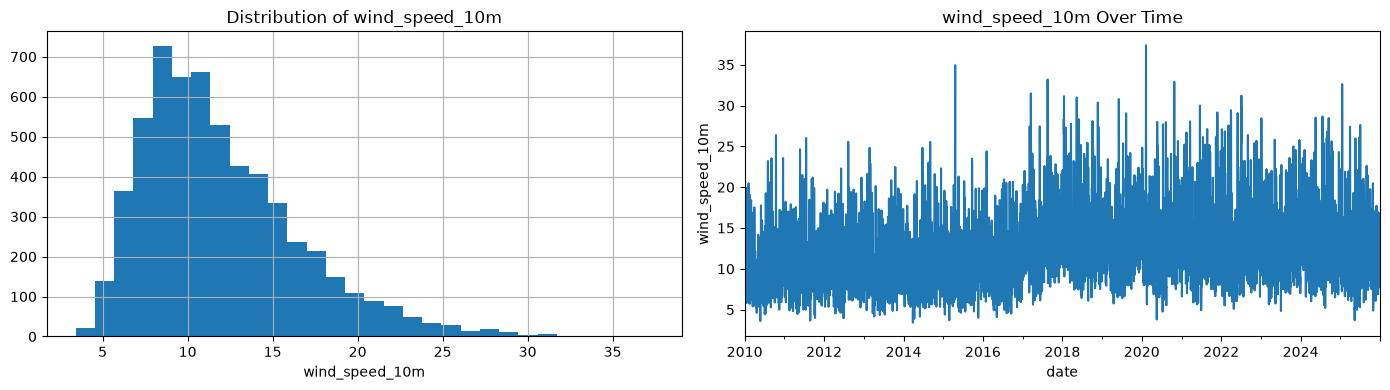

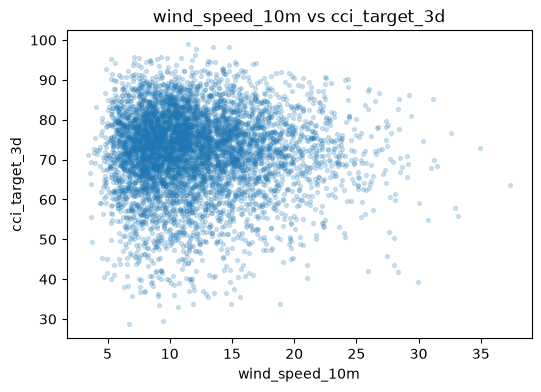

                wind_speed_10m  cci_target_3d
wind_speed_10m        1.000000      -0.013787
cci_target_3d        -0.013787       1.000000


In [37]:
# ------------------------------------------------------------
# C.8 Explore Feature of Interest: Wind Speed
# ------------------------------------------------------------

# Explore the distribution of daily mean wind speed.
explore_distribution(
    daily,
    "wind_speed_10m"
)

# Examine the relationship between daily mean wind speed
# and the 3-day-ahead CCI target.
explore_feature_vs_target(
    daily,
    "wind_speed_10m",
    "cci_target_3d"
)

In [38]:
feature_3_insights = """
Daily mean wind speed ranges from approximately 3.4 to 37.4 km/h, with
a mean of 11.9 km/h and a median of 11.0 km/h. These central values are
close to the 10 km/h reference value used in the CCI WindScore formula,
indicating that typical daily wind conditions are relatively close to
the defined comfort optimum.

The Pearson correlation between daily mean wind speed and the 3-day-ahead
CCI target is approximately -0.014, indicating an essentially zero linear
association. This does not necessarily mean that wind speed has no effect
on CCI. The WindScore is based on the absolute deviation from 10 km/h, so
both wind speeds below and above the optimum can reduce the score. As a
result, the effects on either side of the optimum can partially cancel
when measured using a simple linear correlation.

This demonstrates that correlation with the target may not fully capture
the importance of a feature when the underlying relationship is
non-linear or non-monotonic.

The relatively small standard deviation of 4.6 km/h also indicates that
daily wind speeds are generally concentrated around the mean, although
some higher-wind observations occur. The contribution of wind speed to
CCI variation will therefore be examined further during feature
engineering and model evaluation.

Because Ridge Regression assumes a linear relationship between the
features and target, transformed representations of wind speed will be
considered to better capture its relationship with CCI. Candidate
transformations, such as logarithmic scaling or deviation from the
10 km/h comfort reference, will be compared during feature engineering.
"""

In [39]:
# Do not modify this code
print_tile(size="h3", key='feature_3_insights', value=feature_3_insights)

### C.9 Explore Feature of Interest `cloud_cover`

count    5844.000000
mean       48.576724
std        29.566720
min         0.000000
25%        24.208333
50%        48.062500
75%        72.416667
max       100.000000
Name: cloud_cover, dtype: float64


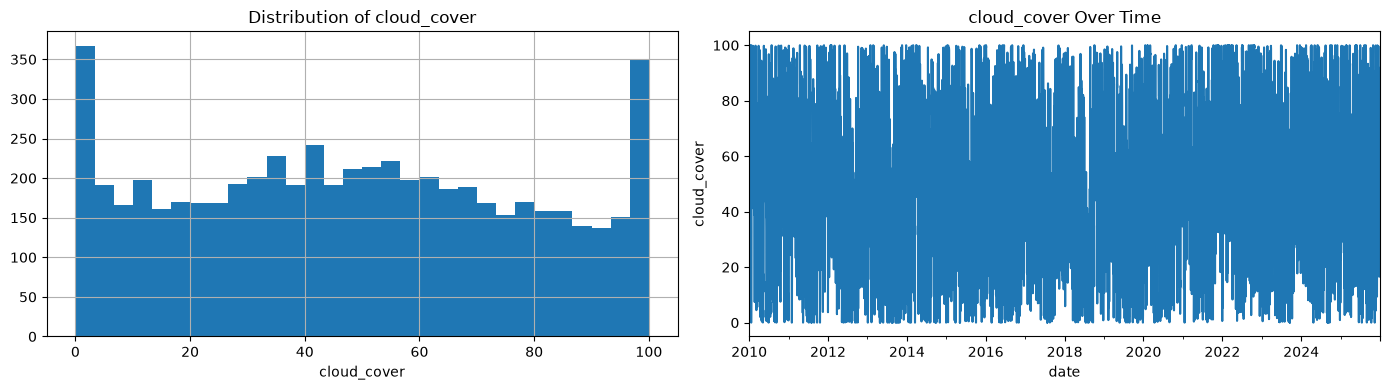

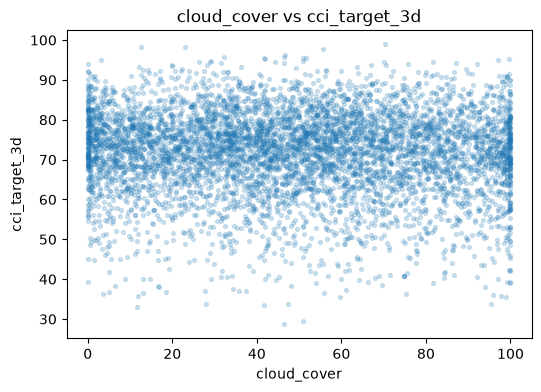

               cloud_cover  cci_target_3d
cloud_cover       1.000000      -0.048439
cci_target_3d    -0.048439       1.000000


In [40]:
# ------------------------------------------------------------
# C.9 Explore Feature of Interest: Cloud Cover
# ------------------------------------------------------------

# Explore the distribution of daily mean cloud cover.
explore_distribution(
    daily,
    "cloud_cover"
)

# Examine the relationship between daily mean cloud cover
# and the 3-day-ahead CCI target.
explore_feature_vs_target(
    daily,
    "cloud_cover",
    "cci_target_3d"
)

In [41]:
feature_4_insights = """
Daily mean cloud cover ranges from 0% to 100%, with a mean of 48.6%
and a median of 48.1%. The standard deviation of 29.6 percentage points
indicates substantial variation in cloud conditions across Sydney's
historical daily observations.

Cloud cover is directly included in the CCI formula through the
CloudScore component, where lower cloud cover represents more favourable
conditions. This suggests that cloud cover should have predictive value
for CCI, although its relationship with the future 3-day-ahead target may
not be fully captured by a simple linear correlation.

The wide range of cloud cover values is useful for modelling because it
provides observations across both clear and heavily overcast conditions.
However, because the CCI scoring function is capped and weighted, the
effect of cloud cover may be smaller than the raw feature range suggests.

The relationship between cloud cover and the 3-day-ahead CCI target will
therefore be assessed using both correlation and model performance.
Cloud cover will be retained as a candidate feature for subsequent
feature engineering and model development.
"""

In [42]:
print_tile(size="h3", key='feature_4_insights', value=feature_4_insights)

### C.10 Explore Feature of Interest: Precipitation

count    5844.000000
mean        2.489511
std         6.850801
min         0.000000
25%         0.000000
50%         0.100000
75%         1.700000
max       138.400000
Name: precipitation, dtype: float64


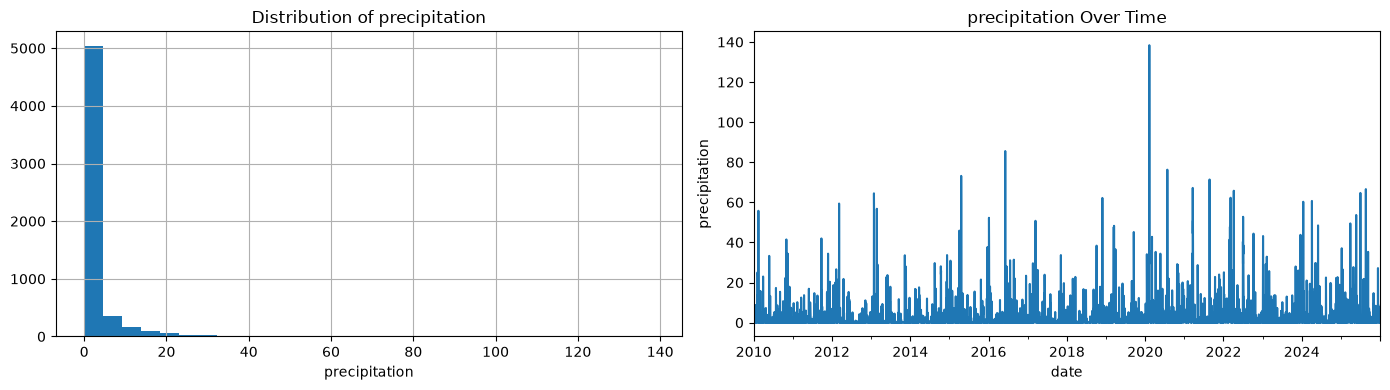

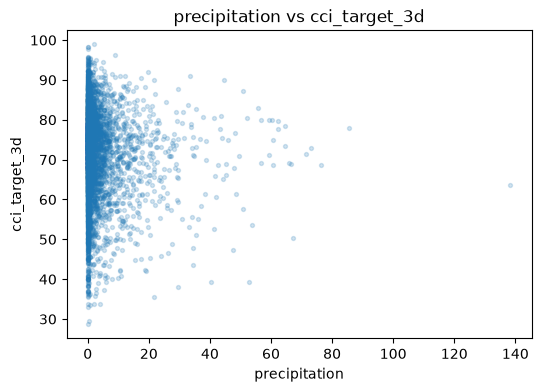

               precipitation  cci_target_3d
precipitation       1.000000      -0.060703
cci_target_3d      -0.060703       1.000000


In [43]:
# ------------------------------------------------------------
# C.10 Explore Feature of Interest: Precipitation
# ------------------------------------------------------------

# Explore the distribution of daily total precipitation.
explore_distribution(
    daily,
    "precipitation"
)

# Examine the relationship between daily total precipitation
# and the 3-day-ahead CCI target.
explore_feature_vs_target(
    daily,
    "precipitation",
    "cci_target_3d"
)

In [44]:
feature_5_insights = """
Daily total precipitation is strongly right-skewed. The median is only
0.1 mm and the first quartile is 0 mm, indicating that at least 25% of
historical days recorded no precipitation. The mean is higher at 2.5 mm,
while the maximum reaches 138.4 mm, demonstrating that a relatively small
number of high-precipitation days contribute substantially to the upper
tail of the distribution.

The Pearson correlation between daily precipitation and the 3-day-ahead
CCI target is approximately -0.061, indicating a very weak negative
linear association. The direction is consistent with the CCI RainScore
formula, where increasing precipitation reduces the precipitation
component of the comfort index.

The weak correlation should not be interpreted as evidence that
precipitation is unimportant. CCI is determined jointly by five weather
components, and the effect of precipitation is non-linear because the
RainScore is capped at zero once precipitation reaches 20 mm.

The strongly right-skewed distribution is an important consideration for
feature engineering. A log1p transformation of precipitation may provide
a more stable representation of the variable for a linear model by
reducing the influence of extreme values. A binary indicator for whether
precipitation occurred may also capture the distinction between dry and
wet days.

These candidate transformations will be evaluated empirically during
feature engineering and model experiments rather than assumed to improve
model performance in advance.
"""

In [45]:
print_tile(size="h3", key='feature_5_insights', value=feature_5_insights)

---
## D. Data Preparation

### D.1 Data Transformation `precipitation_log`

In [46]:
# ------------------------------------------------------------
# D.1 Data Transformation: Log-Transform Precipitation
# ------------------------------------------------------------

# Precipitation is strongly right-skewed, with many observations
# close to zero and a small number of very high-rainfall days.
#
# Apply a log1p transformation:
# log1p(x) = log(1 + x)
#
# log1p is suitable because it handles zero precipitation values
# without producing undefined values.
#
# The transformation compresses large precipitation values and
# reduces the influence of the extreme right tail for models
# that are sensitive to feature scale, such as Ridge Regression.

daily = add_log_transforms(
    daily,
    ["precipitation"]
)

# Compare the raw and transformed precipitation distributions.
daily[["precipitation", "precipitation_log"]].describe()

,precipitation,precipitation_log
count,5844.000000,5844.000000
mean,2.489511,0.621766
std,6.850801,0.906030
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.100000,0.095310
75%,1.700000,0.993252
max,138.400000,4.937347


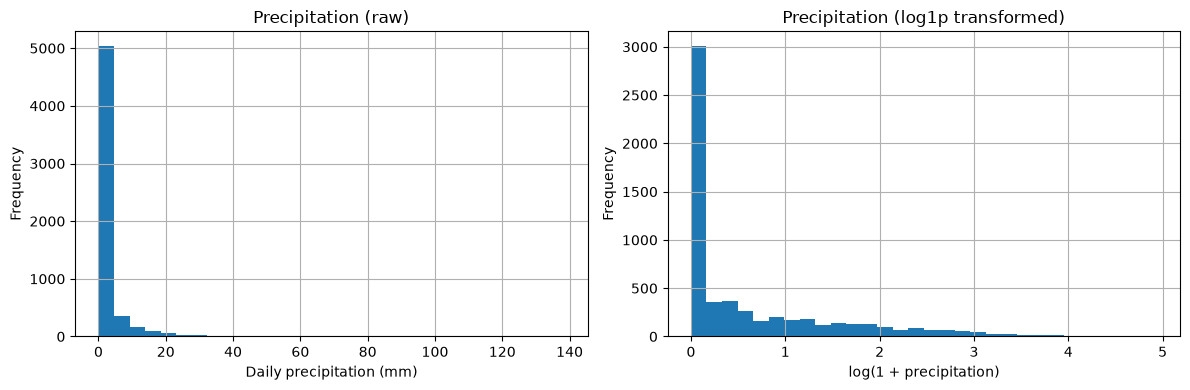

In [47]:
# Compare the raw and log-transformed precipitation distributions.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

daily["precipitation"].hist(bins=30, ax=axes[0])
axes[0].set_title("Precipitation (raw)")
axes[0].set_xlabel("Daily precipitation (mm)")
axes[0].set_ylabel("Frequency")

daily["precipitation_log"].hist(bins=30, ax=axes[1])
axes[1].set_title("Precipitation (log1p transformed)")
axes[1].set_xlabel("log(1 + precipitation)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [48]:
data_cleaning_1_explanations = """
No missing values, duplicate observations, or invalid weather values were
identified during data understanding, so no data-cleaning corrections were
required.

The first preparation step was data transformation. Precipitation was
identified during exploratory analysis as strongly right-skewed, with
many observations close to zero and a small number of extreme rainfall
events.

A log1p transformation was applied to create `precipitation_log`. This
transformation compresses large precipitation values while preserving
zero values because it is calculated as log(1 + x). The maximum value was
reduced from 138.4 mm to approximately 4.94, while the standard deviation
decreased from 6.85 to approximately 0.91.

The transformation is deterministic and uses only the observed
precipitation values, so it does not introduce target leakage and can be
performed before the chronological train-validation-test split. Its
predictive value will be assessed later through feature selection and
model evaluation.
"""

In [49]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### D.2 Data Transformation `wind_speed_10m`

In [50]:
# ------------------------------------------------------------
# D.2 Data Transformation: Log-Transform Wind Speed
# ------------------------------------------------------------

# Check the skewness of the main CCI weather features.
daily[
    [
        "temperature_2m",
        "relative_humidity_2m",
        "wind_speed_10m",
        "cloud_cover",
        "precipitation",
    ]
].skew()

temperature_2m          0.065922
relative_humidity_2m   -0.758064
wind_speed_10m          1.055654
cloud_cover             0.065212
precipitation           6.172261
dtype: float64

In [51]:
# Wind speed has substantial positive (right) skew.
# Apply a log1p transformation to compress the upper tail.

daily = add_log_transforms(
    daily,
    ["wind_speed_10m"]
)

# Compare skewness before and after transformation.
daily[
    ["wind_speed_10m", "wind_speed_10m_log"]
].skew()

wind_speed_10m        1.055654
wind_speed_10m_log    0.173990
dtype: float64

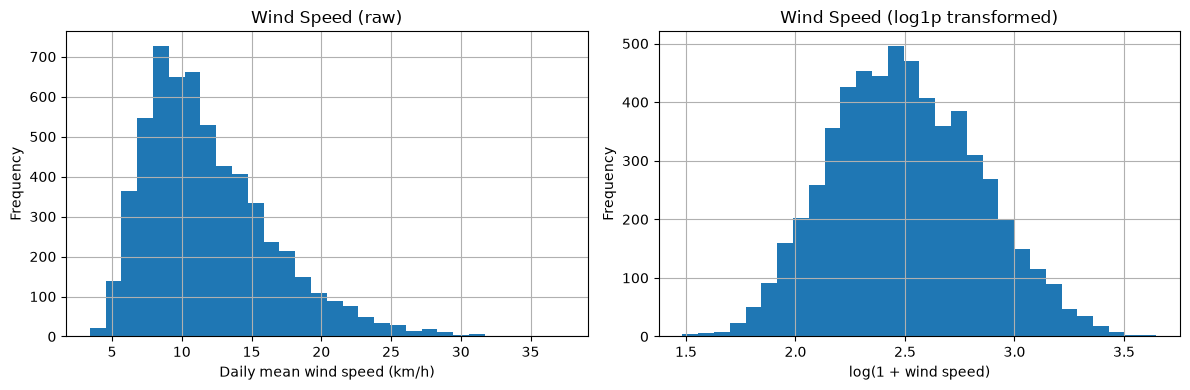

In [52]:
# Compare the raw and log-transformed wind-speed distributions.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

daily["wind_speed_10m"].hist(bins=30, ax=axes[0])
axes[0].set_title("Wind Speed (raw)")
axes[0].set_xlabel("Daily mean wind speed (km/h)")
axes[0].set_ylabel("Frequency")

daily["wind_speed_10m_log"].hist(bins=30, ax=axes[1])
axes[1].set_title("Wind Speed (log1p transformed)")
axes[1].set_xlabel("log(1 + wind speed)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [53]:
data_cleaning_2_explanations = """
Daily mean wind speed showed substantial positive skew, with a skewness
of approximately 1.06. This indicates that the distribution has a longer
right tail caused by relatively high-wind observations.

A log1p transformation was applied to wind_speed_10m to compress the
upper tail and produce a more balanced feature distribution. The
transformation reduced the skewness from approximately 1.06 to 0.17,
representing a substantial reduction in asymmetry.

The transformation is particularly relevant for the Ridge Regression
experiment because reducing the influence of extreme feature values can
provide a more stable representation for a linear model.

The transformed wind-speed feature will be evaluated during the model
experiments to determine whether it improves predictive performance.
"""

In [54]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

---
## E. Feature Engineering

### E.1 New Feature `temp_deviation_from_optimal`

In [55]:
# ------------------------------------------------------------
# E.1 New Feature: Temperature Deviation from Optimal
# ------------------------------------------------------------

# The CCI temperature component is highest at 22°C and decreases
# as temperature moves further away from this optimal value.
#
# Encode this relationship directly by calculating the absolute
# distance between daily mean temperature and 22°C.

daily["temp_deviation_from_optimal"] = np.abs(
    daily["temperature_2m"] - 22
)

# Inspect the raw temperature and engineered feature.
daily[
    ["temperature_2m", "temp_deviation_from_optimal"]
].describe()

,temperature_2m,temp_deviation_from_optimal
count,5844.000000,5844.000000
mean,17.558109,5.005018
std,4.225572,3.540443
min,7.625000,0.000000
25%,13.929167,1.791667
50%,17.666667,4.472917
75%,20.942708,8.091667
max,30.904167,14.375000


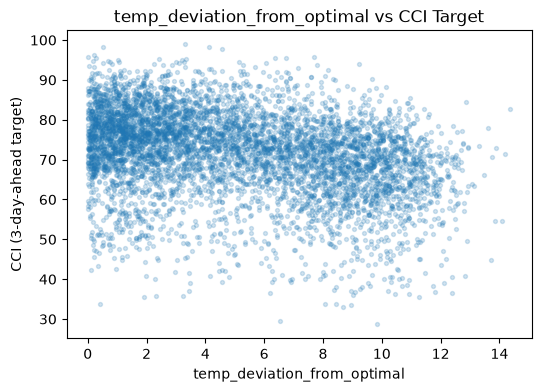

,temp_deviation_from_optimal,cci_target_3d
temp_deviation_from_optimal,1.000000,-0.328674
cci_target_3d,-0.328674,1.000000


In [56]:
plt.figure(figsize=(6, 4))
plt.scatter(daily["temp_deviation_from_optimal"], daily["cci_target_3d"], alpha=0.2, s=8)
plt.xlabel("temp_deviation_from_optimal")
plt.ylabel("CCI (3-day-ahead target)")
plt.title("temp_deviation_from_optimal vs CCI Target")
plt.show()

daily[["temp_deviation_from_optimal", "cci_target_3d"]].corr()

In [57]:
# <Student to fill this section>

feature_engineering_1_explanations = """
Temperature has a non-monotonic relationship with CCI because the
TempScore is highest at the defined optimal temperature of 22°C and
decreases as temperature moves further away from this value. A raw
temperature feature therefore does not directly represent the structure
of the target relationship.

The engineered feature temp_deviation_from_optimal represents the
absolute distance between daily mean temperature and 22°C. Larger values
indicate that the observed temperature is further from the defined
comfort optimum.

This representation is particularly suitable for a linear model such as
Ridge Regression because it converts the two-sided relationship between
temperature and comfort into a single directional relationship: greater
temperature deviation should correspond to lower CCI.

The data provides supporting evidence for this transformation. The
correlation between temp_deviation_from_optimal and the 3-day-ahead CCI
target is approximately -0.329, compared with +0.311 for the raw
temperature feature. This indicates that the engineered feature has a
stronger linear association with the target than raw temperature.

The feature will therefore be retained for the subsequent modelling
experiments. Its contribution to predictive performance and model
interpretation will be assessed using the trained models rather than
being assumed from correlation alone.
"""

In [58]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### E.2 New Feature `humidity_deviation_from_optimal`

In [59]:
# ------------------------------------------------------------
# E.2 New Feature: Humidity Deviation from Optimal
# ------------------------------------------------------------

# The CCI HumidityScore is highest at 50% relative humidity
# and decreases as humidity moves further away from this value.
#
# Encode this relationship as the absolute distance from the
# formula-defined optimal humidity level.

daily["humidity_deviation_from_optimal"] = np.abs(
    daily["relative_humidity_2m"] - 50
)

# Inspect the original and engineered features.
daily[
    ["relative_humidity_2m", "humidity_deviation_from_optimal"]
].describe()

,relative_humidity_2m,humidity_deviation_from_optimal
count,5844.000000,5844.000000
mean,72.579127,23.033097
std,11.000282,10.014793
min,23.875000,0.041667
25%,66.125000,16.291667
50%,74.250000,24.250000
75%,80.760417,30.760417
max,96.041667,46.041667


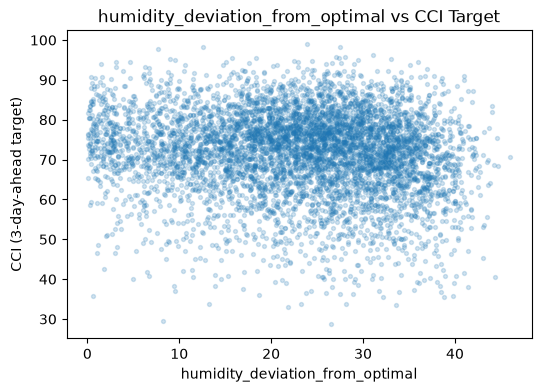

,humidity_deviation_from_optimal,cci_target_3d
humidity_deviation_from_optimal,1.000000,-0.118996
cci_target_3d,-0.118996,1.000000


In [60]:
plt.figure(figsize=(6, 4))
plt.scatter(daily["humidity_deviation_from_optimal"], daily["cci_target_3d"], alpha=0.2, s=8)
plt.xlabel("humidity_deviation_from_optimal")
plt.ylabel("CCI (3-day-ahead target)")
plt.title("humidity_deviation_from_optimal vs CCI Target")
plt.show()

daily[["humidity_deviation_from_optimal", "cci_target_3d"]].corr()

In [61]:
# <Student to fill this section>

feature_engineering_2_explanations = """
Relative humidity has a peaked relationship with CCI by construction
because the HumidityScore is highest at 50% relative humidity and
decreases as humidity moves further away from this reference value.
The humidity_deviation_from_optimal feature represents this relationship
directly as the absolute distance from 50%.

However, unlike the temperature deviation feature, this transformation
did not strengthen the linear association with the 3-day-ahead CCI
target. The raw relative_humidity_2m feature has a correlation of
approximately -0.132 with the target, while
humidity_deviation_from_optimal has a correlation of approximately
-0.119.

One possible explanation is the distribution of humidity in the
historical data. The mean humidity is 72.6% and the median is 74.3%,
indicating that observations are concentrated substantially above the
50% comfort reference. In this observed range, humidity and its absolute
deviation from 50% have a similar monotonic relationship, so the
transformation provides limited additional linear information.

This result demonstrates that a theoretically appropriate transformation
does not necessarily improve the empirical relationship with the target.
The humidity deviation feature will therefore be treated as a candidate
feature and its usefulness will be determined through the subsequent
model experiments rather than being automatically retained.
"""


In [62]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### E.3 New Feature `temperature_3d_rolling_mean`

In [63]:
# ------------------------------------------------------------
#  E.3 New Feature `temperature_3d_rolling_mean`
# ------------------------------------------------------------

# Weather conditions have temporal persistence, so recent temperatures
# may contain useful information for predicting near-future CCI.
# This feature calculates a 3-day backward-looking rolling mean.

daily["temperature_3d_rolling_mean"] = (
    daily["temperature_2m"]
    .rolling(window=3)
    .mean()
)

# Check the distribution of the engineered feature
daily[["temperature_2m", "temperature_3d_rolling_mean"]].describe()

,temperature_2m,temperature_3d_rolling_mean
count,5844.000000,5842.000000
mean,17.558109,17.556900
std,4.225572,4.061324
min,7.625000,8.344444
25%,13.929167,13.957292
50%,17.666667,17.775000
75%,20.942708,20.980208
max,30.904167,28.277778


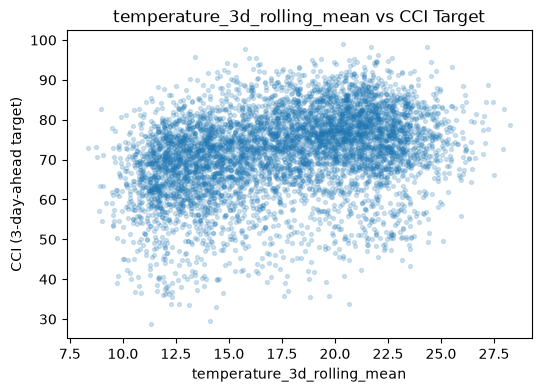

,temperature_3d_rolling_mean,cci_target_3d
temperature_3d_rolling_mean,1.000000,0.327894
cci_target_3d,0.327894,1.000000


In [64]:
plt.figure(figsize=(6, 4))
plt.scatter(daily["temperature_3d_rolling_mean"], daily["cci_target_3d"], alpha=0.2, s=8)
plt.xlabel("temperature_3d_rolling_mean")
plt.ylabel("CCI (3-day-ahead target)")
plt.title("temperature_3d_rolling_mean vs CCI Target")
plt.show()

daily[["temperature_3d_rolling_mean", "cci_target_3d"]].corr()

In [65]:
# <Student to fill this section>
feature_engineering_3_explanations = """
Weather conditions have temporal persistence, meaning recent observations
may contain information about near-future conditions. The
temperature_3d_rolling_mean feature captures the average temperature over
the current day and the previous two days rather than relying only on a
single daily observation.

The rolling window is calculated in the backward direction, so for a given
prediction date it uses only temperature observations from that date and
the two preceding days. It therefore does not use future observations from
D+1, D+2, or D+3.

The first two observations have missing rolling means because three days
of historical observations are required to calculate the feature. These
rows will be handled when the final modelling dataset is prepared.

The engineered feature has a Pearson correlation of approximately 0.328
with the 3-day-ahead CCI target, compared with approximately 0.311 for
raw daily temperature. This represents a small increase in linear
association and suggests that recent temperature conditions may provide
some additional predictive signal.

However, correlation alone does not establish whether the feature improves
forecasting performance. Its usefulness will therefore be evaluated using
the chronological validation and test results of the machine learning
models.
"""

print(feature_engineering_3_explanations)


Weather conditions have temporal persistence, meaning recent observations
may contain information about near-future conditions. The
temperature_3d_rolling_mean feature captures the average temperature over
the current day and the previous two days rather than relying only on a
single daily observation.

The rolling window is calculated in the backward direction, so for a given
prediction date it uses only temperature observations from that date and
the two preceding days. It therefore does not use future observations from
D+1, D+2, or D+3.

The first two observations have missing rolling means because three days
of historical observations are required to calculate the feature. These
rows will be handled when the final modelling dataset is prepared.

The engineered feature has a Pearson correlation of approximately 0.328
with the 3-day-ahead CCI target, compared with approximately 0.311 for
raw daily temperature. This represents a small increase in linear
association and suggests that 

In [66]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_3_explanations', value=feature_engineering_3_explanations)

### E.4 New Feature `temperature_lag1`

In [67]:

# ------------------------------------------------------------
#  E.4 New Feature `temperature_lag1`
# ------------------------------------------------------------

daily["temperature_2m_lag1"] = daily["temperature_2m"].shift(1)

daily[["temperature_2m", "temperature_2m_lag1"]].describe()

,temperature_2m,temperature_2m_lag1
count,5844.000000,5843.000000
mean,17.558109,17.557783
std,4.225572,4.225860
min,7.625000,7.625000
25%,13.929167,13.929167
50%,17.666667,17.662500
75%,20.942708,20.943750
max,30.904167,30.904167


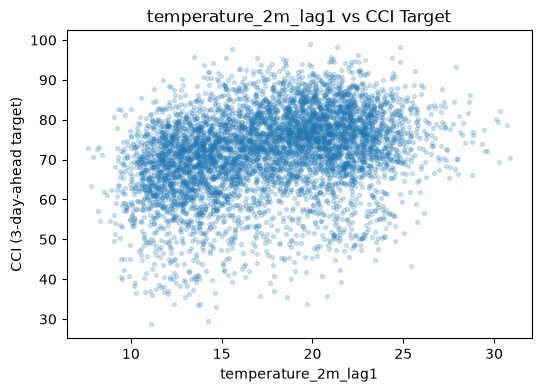

,temperature_2m_lag1,cci_target_3d
temperature_2m_lag1,1.000000,0.317978
cci_target_3d,0.317978,1.000000


In [68]:
plt.figure(figsize=(6, 4))
plt.scatter(daily["temperature_2m_lag1"], daily["cci_target_3d"], alpha=0.2, s=8)
plt.xlabel("temperature_2m_lag1")
plt.ylabel("CCI (3-day-ahead target)")
plt.title("temperature_2m_lag1 vs CCI Target")
plt.show()

daily[["temperature_2m_lag1", "cci_target_3d"]].corr()

In [69]:
feature_engineering_4_explanations = """
temperature_2m_lag1 uses shift(1) to pull yesterday's raw temperature
into today's row as a separate feature, distinct from the rolling mean
tested earlier (F.3) which blends recent days into one averaged value.
This uses only information available at prediction time (a genuinely
past value), so it carries no temporal leakage risk.

The correlation with the CCI target is r = 0.318, very close to raw
temperature_2m's r = 0.307, and similarly close to
temperature_3d_rolling_mean's r = 0.326 (already rejected as redundant
in F.3). This is consistent with the earlier finding: Sydney's
day-to-day temperature is highly persistent (yesterday's mean and
today's mean are nearly identical, as shown by their summary statistics
above -- mean 17.56 vs 17.56, virtually unchanged), so a single day's
lag adds little distinct information beyond what today's own
temperature already captures. This is expected given how slowly
temperature typically changes day-to-day relative to the 3-day
forecast horizon, and mirrors the same redundancy pattern already
identified with the rolling mean feature.
"""

In [70]:
print_tile(size="h3", key='feature_engineering_4_explanations', value=feature_engineering_4_explanations)

### E.5 New Feature `temperature_lag2`

In [71]:
daily["temperature_2m_lag2"] = daily["temperature_2m"].shift(2)

daily[["temperature_2m", "temperature_2m_lag2"]].describe()

,temperature_2m,temperature_2m_lag2
count,5844.000000,5842.000000
mean,17.558109,17.557570
std,4.225572,4.226191
min,7.625000,7.625000
25%,13.929167,13.929167
50%,17.666667,17.662500
75%,20.942708,20.944792
max,30.904167,30.904167


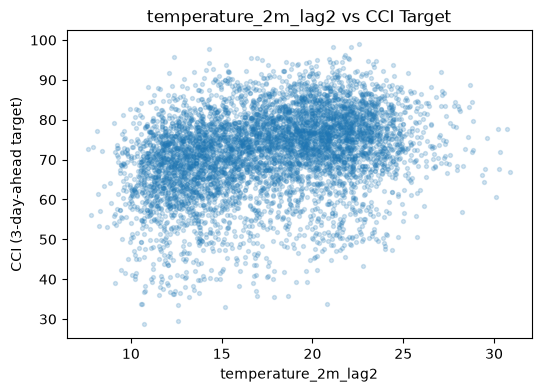

,temperature_2m_lag2,cci_target_3d
temperature_2m_lag2,1.000000,0.317319
cci_target_3d,0.317319,1.000000


In [72]:
plt.figure(figsize=(6, 4))
plt.scatter(daily["temperature_2m_lag2"], daily["cci_target_3d"], alpha=0.2, s=8)
plt.xlabel("temperature_2m_lag2")
plt.ylabel("CCI (3-day-ahead target)")
plt.title("temperature_2m_lag2 vs CCI Target")
plt.show()

daily[["temperature_2m_lag2", "cci_target_3d"]].corr()

In [73]:
feature_engineering_5_explanations = """
temperature_2m_lag2 uses shift(2) to pull the temperature from two days
before today's row, testing whether a slightly longer look-back adds
information beyond a single day's lag. Like lag1, this uses only past
information and carries no temporal leakage risk.

The correlation with the CCI target is r = 0.317, virtually identical to
lag1's r = 0.318 and raw temperature_2m's r = 0.307. Increasing the lag
from 1 to 2 days made no meaningful difference, confirming that Sydney's
temperature persists very consistently over these short timescales --
the summary statistics again show almost no change in the underlying
distribution (mean 17.56 for both raw and lag2), so there is little
day-to-day variation for a longer lag to meaningfully re-express.

Taken together, temperature_2m, temperature_2m_lag1, and
temperature_2m_lag2 form a fourth mutually redundant group in this
notebook (alongside the earlier temperature/temp_deviation/rolling_mean
trio identified in Section F's correlation heatmap), all carrying
near-identical information about the same underlying quantity. Neither
lag feature is retained in the final feature set: they add no
meaningful signal beyond what temp_deviation_from_optimal (the strongest
and formula-motivated member of this redundant group) already provides,
and including them would only reintroduce the multicollinearity concern
that was specifically resolved during feature selection (Section G).
"""

In [74]:
print_tile(size="h3", key='feature_engineering_5_explanations', value=feature_engineering_5_explanations)

---
## F. Data Preparation for Modeling

### F.1 Split Datasets

In [75]:
# Chronological split -- required for time series data. Random splitting
# would leak future information into training (e.g. training on 2023 data
# while validating on 2020 data), which would produce misleadingly
# optimistic validation performance that wouldn't hold up in production.

daily = daily.sort_values("date").reset_index(drop=True)

n = len(daily)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = daily.iloc[:train_end].copy()
val = daily.iloc[train_end:val_end].copy()
test = daily.iloc[val_end:].copy()

print(f"Train: {train.shape[0]} rows, {train['date'].min()} to {train['date'].max()}")
print(f"Val:   {val.shape[0]} rows, {val['date'].min()} to {val['date'].max()}")
print(f"Test:  {test.shape[0]} rows, {test['date'].min()} to {test['date'].max()}")

Train: 4090 rows, 2010-01-01 00:00:00 to 2021-03-13 00:00:00
Val:   877 rows, 2021-03-14 00:00:00 to 2023-08-07 00:00:00
Test:  877 rows, 2023-08-08 00:00:00 to 2025-12-31 00:00:00


In [76]:
# ------------------------------------------------------------
# Create horizon-specific datasets
# ------------------------------------------------------------

# Each forecasting horizon has a different number of missing
# target values at the end of the historical dataset.
#
# The chronological train/validation/test boundaries remain
# identical across all horizons.

train_1d = train.dropna(subset=["cci_target_1d"]).reset_index(drop=True)

val_1d = val.dropna(subset=["cci_target_1d"]).reset_index(drop=True)

test_1d = test.dropna(subset=["cci_target_1d"]).reset_index(drop=True)


train_2d = train.dropna(subset=["cci_target_2d"]).reset_index(drop=True)

val_2d = val.dropna(subset=["cci_target_2d"]).reset_index(drop=True)

test_2d = test.dropna(subset=["cci_target_2d"]).reset_index(drop=True)


train_3d = train.dropna(subset=["cci_target_3d"]).reset_index(drop=True)

val_3d = val.dropna(subset=["cci_target_3d"]).reset_index(drop=True)

test_3d = test.dropna(subset=["cci_target_3d"]).reset_index(drop=True)


# Display the number of usable observations for each horizon.
print("Usable observations by forecasting horizon:")
print(f"+1 day - Train: {len(train_1d)}, Val: {len(val_1d)}, Test: {len(test_1d)}")
print(f"+2 days - Train: {len(train_2d)}, Val: {len(val_2d)}, Test: {len(test_2d)}")
print(f"+3 days - Train: {len(train_3d)}, Val: {len(val_3d)}, Test: {len(test_3d)}")

Usable observations by forecasting horizon:
+1 day - Train: 4090, Val: 877, Test: 876
+2 days - Train: 4090, Val: 877, Test: 875
+3 days - Train: 4090, Val: 877, Test: 874


In [77]:
data_splitting_explanations = """
The dataset was split chronologically into train (70%), validation (15%),
and test (15%) sets rather than randomly because this is a time-series
forecasting problem. A random split could allow information from later
periods to appear in the training data while earlier periods appear in
validation or test data, producing an unrealistic estimate of forecasting
performance. The chronological split ensures that the model is always
evaluated on periods that occur after the data used for training.

The resulting splits are:
- Train: 4,090 rows, 2010-01-01 to 2021-03-13
- Validation: 877 rows, 2021-03-14 to 2023-08-07
- Test: 877 rows, 2023-08-08 to 2025-12-31

Each split represents a distinct, non-overlapping time period, with the
training period preceding the validation period and the validation period
preceding the test period.

After splitting, rows with unavailable future CCI targets were removed
separately for each forecasting horizon. These missing values are a
structural consequence of the forward shifts used to create the 1-day,
2-day, and 3-day-ahead targets.

For the 3-day-ahead target, the final three dates in the complete dataset
(2025-12-29 to 2025-12-31) do not have corresponding future CCI values
because those target dates would fall in 2026, outside the available
modelling period. These rows occur in the test set, reducing it from 877
to 874 usable observations. Similarly, the +1-day and +2-day test sets
contain 876 and 875 usable observations respectively.

The training and validation sets remain unchanged because their required
future target values are available within the historical dataset.
"""

In [78]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### F.2 Feature Selection "Pearson correlation"

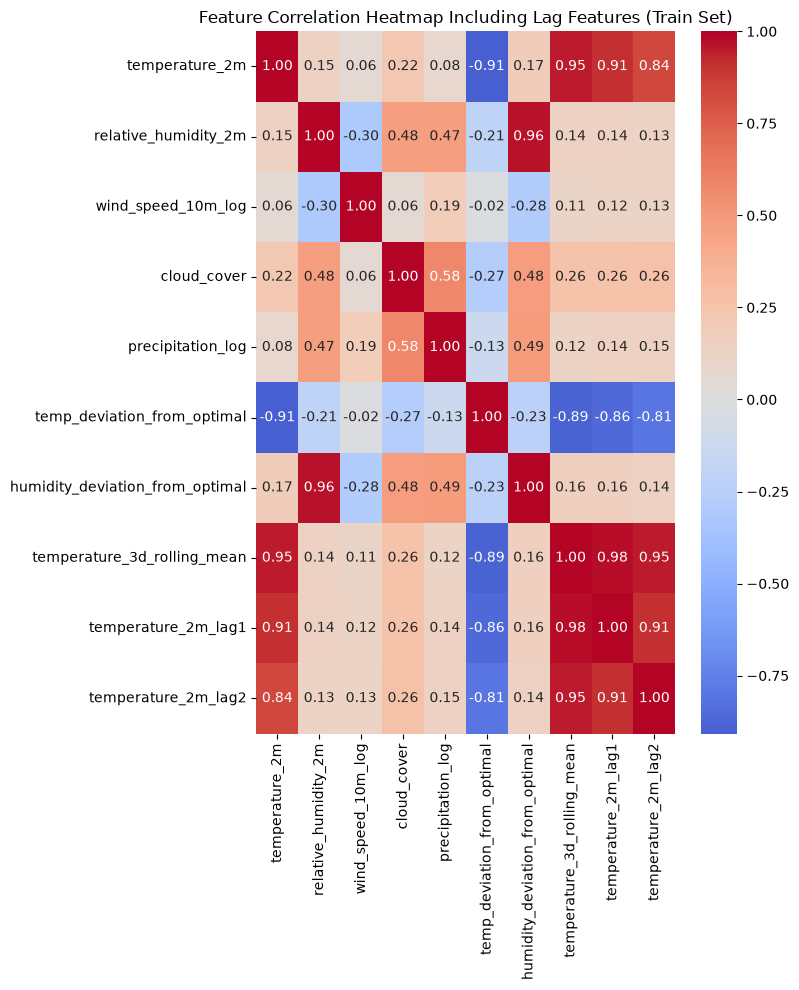

,temperature_2m_lag1,temperature_2m_lag2
temperature_2m,0.909510,0.839716
relative_humidity_2m,0.138768,0.131735
wind_speed_10m_log,0.124732,0.127883
cloud_cover,0.258742,0.263501
precipitation_log,0.138302,0.145360
temp_deviation_from_optimal,-0.855529,-0.806982
humidity_deviation_from_optimal,0.158969,0.135960
temperature_3d_rolling_mean,0.977454,0.953266
temperature_2m_lag1,1.000000,0.909484
temperature_2m_lag2,0.909484,1.000000


In [79]:
candidate_features_with_lags = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m_log",
    "cloud_cover",
    "precipitation_log",
    "temp_deviation_from_optimal",
    "humidity_deviation_from_optimal",
    "temperature_3d_rolling_mean",
    "temperature_2m_lag1",
    "temperature_2m_lag2",
]

corr_with_lags = train[candidate_features_with_lags].corr()

plt.figure(figsize=(8,10))
sns.heatmap(corr_with_lags, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap Including Lag Features (Train Set)")
plt.tight_layout()
plt.show()

corr_with_lags[["temperature_2m_lag1", "temperature_2m_lag2"]]

In [80]:
selected_features = [
    "temp_deviation_from_optimal",
    "relative_humidity_2m",
    "wind_speed_10m_log",
    "cloud_cover",
    "precipitation_log",
]

In [81]:
# <Student to fill this section>
data_transformation_1_explanations = """

Feature selection was performed using the training set only, ensuring that
validation and test data were not used when selecting features. The
correlation heatmap was used to identify redundant features and
multicollinearity among the candidate predictors.

Three temperature-related features showed strong correlations with each
other. temperature_2m and temp_deviation_from_optimal had a correlation of
r = -0.908, temperature_2m and temperature_3d_rolling_mean had a
correlation of r = 0.953, and temp_deviation_from_optimal and
temperature_3d_rolling_mean had a correlation of r = -0.891.
temp_deviation_from_optimal was retained because it had the strongest
absolute correlation with the CCI target (r = -0.331) and directly
represents the distance from the CCI's optimal temperature of 22°C.
temperature_2m and temperature_3d_rolling_mean were therefore removed as
redundant temperature representations.

A similar pattern occurred for humidity. relative_humidity_2m and
humidity_deviation_from_optimal had a very strong correlation of
r = 0.964. relative_humidity_2m was retained because it had a slightly
stronger absolute correlation with the target (|r| = 0.110 versus
|r| = 0.103) and provides a more direct interpretation of the observed
humidity level. humidity_deviation_from_optimal was therefore removed as
redundant.

The remaining features, cloud_cover, precipitation_log, and
wind_speed_10m_log, were retained because they represent different weather
characteristics and do not exhibit the same severe multicollinearity as the
temperature and humidity feature groups. Although their individual
correlations with the target are weak, they remain plausible predictors
because each represents a distinct component of the CCI calculation.

The final selected feature set is:

- temp_deviation_from_optimal
- relative_humidity_2m
- wind_speed_10m_log
- cloud_cover
- precipitation_log

The final feature set will be evaluated using the chronological validation
and test datasets to determine whether these predictors provide useful
forecasting performance.


temperature_2m_lag1 and temperature_2m_lag2 were tested as candidate
additions after the original feature selection (Section G) was already
finalised. The extended correlation heatmap confirms both lag features
are severely correlated with the temperature group already identified
as redundant in Section G: temperature_2m_lag1 correlates with raw
temperature_2m at r=0.91, with temp_deviation_from_optimal at r=-0.86,
and with temperature_3d_rolling_mean at r=0.98 (temperature_2m_lag2
shows a similar, only slightly weaker pattern). Both lag features
therefore belong to the same mutually redundant temperature group as
temperature_2m and temperature_3d_rolling_mean, which were already
excluded in favour of temp_deviation_from_optimal.

Given this confirmation, and the earlier finding that both lag features'
correlation with the CCI target (r=0.318, r=0.317) offered no
improvement over temp_deviation_from_optimal (r=-0.331) or raw
temperature_2m (r=0.307), the original selected_features list from
Section G is retained unchanged:
"""

In [82]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

### F.3 Data Transformation "Scaling"

In [83]:
# <Student to fill this section>
data_transformation_2_explanations = """
Feature scaling is performed inside the modeling pipeline (Section J)
rather than as a standalone preprocessing step. For the Ridge model,
scikit-learn's Pipeline will combine StandardScaler with Ridge into a
single fitted object.

This approach ensures that the scaler is fitted using the training data
only and that the same fitted transformation is then applied to the
validation and test data. This prevents information from the validation or
test periods from influencing the scaling parameters and avoids data
leakage.

Using a Pipeline also ensures that scaling is applied consistently whenever
the trained model is used for prediction, including predictions made by
the deployed API. This reduces the risk of the preprocessing and model
becoming mismatched or the scaling step being accidentally omitted for
new observations.

Scaling is particularly relevant for Ridge Regression because its
regularisation is sensitive to the scale of the input features. The
pipeline therefore provides a consistent and leakage-safe way to prepare
the selected features before fitting the Ridge model.
"""

In [84]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_2_explanations', value=data_transformation_2_explanations)

---
## G. Save Datasets

In [85]:
## G. Save Datasets

data_final_path = '../../data/processed/comfort_climate'

# ------------------------------------------------------------
# +1 day target
# ------------------------------------------------------------
X_train_1d = train_1d[selected_features]
X_val_1d = val_1d[selected_features]
X_test_1d = test_1d[selected_features]

y_train_1d = train_1d["cci_target_1d"]
y_val_1d = val_1d["cci_target_1d"]
y_test_1d = test_1d["cci_target_1d"]


# ------------------------------------------------------------
# +2 day target
# ------------------------------------------------------------
X_train_2d = train_2d[selected_features]
X_val_2d = val_2d[selected_features]
X_test_2d = test_2d[selected_features]

y_train_2d = train_2d["cci_target_2d"]
y_val_2d = val_2d["cci_target_2d"]
y_test_2d = test_2d["cci_target_2d"]


# ------------------------------------------------------------
# +3 day target
# ------------------------------------------------------------
X_train_3d = train_3d[selected_features]
X_val_3d = val_3d[selected_features]
X_test_3d = test_3d[selected_features]

y_train_3d = train_3d["cci_target_3d"]
y_val_3d = val_3d["cci_target_3d"]
y_test_3d = test_3d["cci_target_3d"]


print("Dataset shapes:")
print("+1 day:", X_train_1d.shape, y_train_1d.shape,
      X_val_1d.shape, y_val_1d.shape,
      X_test_1d.shape, y_test_1d.shape)

print("+2 days:", X_train_2d.shape, y_train_2d.shape,
      X_val_2d.shape, y_val_2d.shape,
      X_test_2d.shape, y_test_2d.shape)

print("+3 days:", X_train_3d.shape, y_train_3d.shape,
      X_val_3d.shape, y_val_3d.shape,
      X_test_3d.shape, y_test_3d.shape)

Dataset shapes:
+1 day: (4090, 5) (4090,) (877, 5) (877,) (876, 5) (876,)
+2 days: (4090, 5) (4090,) (877, 5) (877,) (875, 5) (875,)
+3 days: (4090, 5) (4090,) (877, 5) (877,) (874, 5) (874,)


In [86]:
# Save training, validation, and test sets for all three horizons.
try:
    # +1 day
    X_train_1d.to_csv(f'{data_final_path}/X_train_1d.csv', index=False)
    y_train_1d.to_csv(f'{data_final_path}/y_train_1d.csv', index=False)
    X_val_1d.to_csv(f'{data_final_path}/X_val_1d.csv', index=False)
    y_val_1d.to_csv(f'{data_final_path}/y_val_1d.csv', index=False)
    X_test_1d.to_csv(f'{data_final_path}/X_test_1d.csv', index=False)
    y_test_1d.to_csv(f'{data_final_path}/y_test_1d.csv', index=False)

    # +2 days
    X_train_2d.to_csv(f'{data_final_path}/X_train_2d.csv', index=False)
    y_train_2d.to_csv(f'{data_final_path}/y_train_2d.csv', index=False)
    X_val_2d.to_csv(f'{data_final_path}/X_val_2d.csv', index=False)
    y_val_2d.to_csv(f'{data_final_path}/y_val_2d.csv', index=False)
    X_test_2d.to_csv(f'{data_final_path}/X_test_2d.csv', index=False)
    y_test_2d.to_csv(f'{data_final_path}/y_test_2d.csv', index=False)

    # +3 days
    X_train_3d.to_csv(f'{data_final_path}/X_train_3d.csv', index=False)
    y_train_3d.to_csv(f'{data_final_path}/y_train_3d.csv', index=False)
    X_val_3d.to_csv(f'{data_final_path}/X_val_3d.csv', index=False)
    y_val_3d.to_csv(f'{data_final_path}/y_val_3d.csv', index=False)
    X_test_3d.to_csv(f'{data_final_path}/X_test_3d.csv', index=False)
    y_test_3d.to_csv(f'{data_final_path}/y_test_3d.csv', index=False)

except Exception as e:
    print(e)

---
## I.1. Selection of Performance Metrics

In [87]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
from at2_experiments.modeling.evaluate import evaluate_regression


2026-09-20 18:11:23.782 | INFO     | at2_experiments.config:<module>:11 - PROJ_ROOT path is: /Users/parisakalaki/projects/36120-26SP-AT2-experiments


In [88]:
performance_metrics_explanations = """
Two regression metrics are used to evaluate CCI forecasting performance,
with MAE treated as the primary metric for model comparison and
stakeholder reporting.

- MAE (Mean Absolute Error) is the primary metric because it expresses the
  average prediction error directly in CCI points on the 0-100 scale. For
  example, an MAE of 7 means predictions are typically about 7 CCI points
  away from the observed value. It gives equal weight to each prediction
  error and is therefore easy to interpret.

- RMSE (Root Mean Squared Error) is reported as a secondary metric because
  it penalises larger errors more heavily than MAE. Comparing RMSE with
  MAE helps identify whether the model produces occasional large
  forecasting errors.

MAE is therefore used as the primary metric for selecting and comparing
models, while RMSE provides complementary information about the impact of
larger prediction errors.
"""

In [89]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## I.2. Baseline

In [90]:
from sklearn.dummy import DummyRegressor

# ------------------------------------------------------------
# Mean baseline models for all three forecasting horizons
# ------------------------------------------------------------

baseline_models = {}
baseline_val_metrics = {}

for horizon, X_train, y_train, X_val, y_val in [
    ("1d", X_train_1d, y_train_1d, X_val_1d, y_val_1d),
    ("2d", X_train_2d, y_train_2d, X_val_2d, y_val_2d),
    ("3d", X_train_3d, y_train_3d, X_val_3d, y_val_3d),
]:

    baseline = DummyRegressor(strategy="mean")
    baseline.fit(X_train, y_train)

    val_preds = baseline.predict(X_val)

    baseline_models[horizon] = baseline

    baseline_val_metrics[horizon] = evaluate_regression(
        y_val,
        val_preds,
        f"Baseline +{horizon.replace('d', ' day')} - Validation"
    )

Baseline +1 day - Validation -- MAE: 8.493 (primary), RMSE: 11.143
Baseline +2 day - Validation -- MAE: 8.488 (primary), RMSE: 11.141
Baseline +3 day - Validation -- MAE: 8.486 (primary), RMSE: 11.140


In [91]:
baseline_explanations = """
A DummyRegressor baseline using strategy='mean' was established as a
reference point for Hypothesis H1. The model does not use any weather
features. Instead, it predicts the mean CCI value from the training data
for every observation.

The baseline achieved similar validation performance across the three
forecasting horizons. Validation MAE was 8.493 for +1 day, 8.488 for
+2 days, and 8.486 for +3 days. The corresponding RMSE values were
11.143, 11.141, and 11.140.

These validation results provide reference levels against which the Ridge
models can be compared. A useful forecasting model should improve upon
this feature-free baseline, with MAE treated as the primary metric because
it directly represents average prediction error in CCI points.

The baseline is intentionally simple and does not use weather features.
Therefore, improvement over the baseline provides evidence that the
weather-based features contribute predictive value beyond simply
predicting the average CCI.
"""

In [92]:
print_tile(size="h3", key='baseline_explanations', value=baseline_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

In [93]:
from sklearn.linear_model import Ridge

In [94]:

algorithm_selection_explanations = """
Ridge Regression was selected as the primary machine learning algorithm for
predicting the Climate Comfort Index. The choice is motivated by the
structure of the target variable: the CCI is calculated as a weighted
combination of five component scores for temperature, humidity, wind,
cloud cover, and precipitation. Although the component scores themselves
are derived using non-linear transformations such as absolute deviations
and clipping, the resulting CCI is highly structured and interpretable.
This makes a regularised linear model a suitable first machine learning
approach after CCI-informed feature engineering.

Ridge Regression was chosen instead of ordinary Linear Regression because
the selected predictors can still contain some correlation. For example,
cloud_cover and precipitation_log had a moderate correlation of
approximately r = 0.58 in the training correlation matrix. Ridge applies
L2 regularisation, which can reduce the effect of correlated predictors
and produce more stable coefficient estimates while retaining the
interpretability of a linear model.

Ridge also works naturally with the StandardScaler preprocessing step in
the modelling pipeline. Scaling is important because Ridge regularisation
depends on the scale of the predictors. The pipeline will fit the scaler
and Ridge model using the training data only and then apply the same
transformation to validation, test, and production observations.

Finally, Ridge provides interpretable coefficients that can be reported as
feature contributions in the model metadata required by the assignment.
This provides a transparent alternative to relying only on a black-box
model and supports clearer communication of the factors influencing
predicted CCI.
"""

In [95]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

In [96]:
### J.2 Set Hyperparameters

from sklearn.linear_model import RidgeCV
from sklearn.model_selection import TimeSeriesSplit

# Test a wide range of alpha values using time-series
# cross-validation on the training data only.
alphas = np.logspace(-3, 5, 80)

tscv = TimeSeriesSplit(n_splits=5)


# ------------------------------------------------------------
# +1 day
# ------------------------------------------------------------
ridge_cv_1d = RidgeCV(
    alphas=alphas,
    cv=tscv
)

ridge_cv_1d.fit(X_train_1d, y_train_1d)

print(f"Best alpha (+1 day): {ridge_cv_1d.alpha_:.4f}")


# ------------------------------------------------------------
# +2 days
# ------------------------------------------------------------
ridge_cv_2d = RidgeCV(
    alphas=alphas,
    cv=tscv
)

ridge_cv_2d.fit(X_train_2d, y_train_2d)

print(f"Best alpha (+2 days): {ridge_cv_2d.alpha_:.4f}")


# ------------------------------------------------------------
# +3 days
# ------------------------------------------------------------
ridge_cv_3d = RidgeCV(
    alphas=alphas,
    cv=tscv
)

ridge_cv_3d.fit(X_train_3d, y_train_3d)

print(f"Best alpha (+3 days): {ridge_cv_3d.alpha_:.4f}")

Best alpha (+1 day): 22.6168
Best alpha (+2 days): 17.9128
Best alpha (+3 days): 1898.8078


In [97]:
hyperparameters_selection_explanations = """
Ridge Regression has one primary hyperparameter, alpha, which controls the strength of L2 regularisation. A low alpha applies weaker regularisation, while a higher alpha applies stronger coefficient shrinkage.

RidgeCV was used to select alpha rather than choosing the value manually. A range of 80 alpha values, logarithmically spaced from 0.001 to 100,000, was evaluated using five-fold TimeSeriesSplit cross-validation. TimeSeriesSplit was selected because this is a time-series forecasting problem and the temporal ordering of observations should be preserved during cross-validation.

The cross-validation was performed using the training data only, keeping the separate validation and test periods independent from hyperparameter selection. The procedure selected an alpha value of 1898.8078. This indicates that relatively strong regularisation was preferred within the tested range for the selected feature set.

The selected alpha will be used for the Ridge model evaluation on the chronological validation set. The test set will remain untouched until final model evaluation.
"""

In [98]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [99]:
# ------------------------------------------------------------
# J.3 Fit Ridge Models
# ------------------------------------------------------------

# +1 day Ridge model
ridge_pipe_1d = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=ridge_cv_1d.alpha_)),
    ]
)

ridge_pipe_1d.fit(X_train_1d, y_train_1d)


# +2 days Ridge model
ridge_pipe_2d = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=ridge_cv_2d.alpha_)),
    ]
)

ridge_pipe_2d.fit(X_train_2d, y_train_2d)


# +3 days Ridge model
ridge_pipe_3d = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=ridge_cv_3d.alpha_)),
    ]
)

ridge_pipe_3d.fit(X_train_3d, y_train_3d)

print("Three Ridge models fitted successfully.")

Three Ridge models fitted successfully.


In [100]:
fit_model_explanations = """The final Ridge Regression model was implemented using a scikit-learn Pipeline containing StandardScaler and Ridge Regression. StandardScaler standardises the selected predictor variables before they are passed to the Ridge model. This is important because Ridge regularisation is affected by the scale of the input features.

The Ridge model uses the alpha value selected during the previous time-series cross-validation step. The pipeline is fitted using the training data only. This ensures that the scaling parameters and model coefficients are learned exclusively from the training period.

Using a Pipeline also ensures that the same preprocessing steps are automatically applied when the model is evaluated on the validation and test datasets and when it is later used for production predictions. This reduces the risk of applying inconsistent preprocessing or accidentally introducing data leakage.
"""

In [101]:
print_tile(size="h3", key='fit_model_explanations', value=fit_model_explanations)

### J.4 Model Technical Performance

In [102]:
# ------------------------------------------------------------
# J.4 Model Technical Performance
# ------------------------------------------------------------

# ============================================================
# +1 day
# ============================================================

train_preds_1d = ridge_pipe_1d.predict(X_train_1d)
val_preds_1d = ridge_pipe_1d.predict(X_val_1d)

train_metrics_1d = evaluate_regression(
    y_train_1d,
    train_preds_1d,
    "Ridge +1 day - Train"
)

val_metrics_1d = evaluate_regression(
    y_val_1d,
    val_preds_1d,
    "Ridge +1 day - Validation"
)


# ============================================================
# +2 days
# ============================================================

train_preds_2d = ridge_pipe_2d.predict(X_train_2d)
val_preds_2d = ridge_pipe_2d.predict(X_val_2d)

train_metrics_2d = evaluate_regression(
    y_train_2d,
    train_preds_2d,
    "Ridge +2 days - Train"
)

val_metrics_2d = evaluate_regression(
    y_val_2d,
    val_preds_2d,
    "Ridge +2 days - Validation"
)


# ============================================================
# +3 days
# ============================================================

train_preds_3d = ridge_pipe_3d.predict(X_train_3d)
val_preds_3d = ridge_pipe_3d.predict(X_val_3d)

train_metrics_3d = evaluate_regression(
    y_train_3d,
    train_preds_3d,
    "Ridge +3 days - Train"
)

val_metrics_3d = evaluate_regression(
    y_val_3d,
    val_preds_3d,
    "Ridge +3 days - Validation"
)

Ridge +1 day - Train -- MAE: 5.932 (primary), RMSE: 7.846
Ridge +1 day - Validation -- MAE: 6.361 (primary), RMSE: 8.582
Ridge +2 days - Train -- MAE: 6.749 (primary), RMSE: 8.947
Ridge +2 days - Validation -- MAE: 7.650 (primary), RMSE: 10.048
Ridge +3 days - Train -- MAE: 7.025 (primary), RMSE: 9.246
Ridge +3 days - Validation -- MAE: 7.975 (primary), RMSE: 10.504


In [103]:
model_performance_explanations = """
The final Ridge model used the alpha value of 1898.8078 selected through five-fold TimeSeriesSplit cross-validation. The model achieved an MAE of 7.025 and RMSE of 9.246 on the training set, and an MAE of 7.975 and RMSE of 10.504 on the validation set.

The validation results show that Ridge Regression outperformed the DummyRegressor baseline. The DummyRegressor achieved a validation MAE of 8.486 and RMSE of 11.140, compared with 7.975 MAE and 10.504 RMSE for Ridge. This represents an improvement of approximately 0.51 CCI points in MAE and 0.64 in RMSE. Therefore, the selected weather features provide predictive information beyond simply predicting the training-set mean CCI.

The difference between the Ridge training and validation MAE is approximately 0.95 CCI points (7.025 versus 7.975). Validation error is higher than training error, as expected when evaluating on unseen future observations. The relatively small difference suggests that there is not a large deterioration in performance between the training and validation periods.

RMSE is higher than MAE on both datasets. This indicates that some prediction errors are relatively larger than the typical absolute error because RMSE gives greater weight to larger errors. The specific causes of these larger errors should be investigated through further error analysis rather than assumed.

The validation MAE of 7.975 CCI points is smaller than the 20-point width of each CCI interpretation band. However, predictions close to a boundary between categories may still be assigned to an adjacent interpretation band because of prediction error.

Overall, the validation results support H1 because the Ridge model achieved a lower validation MAE than the DummyRegressor baseline. Final confirmation of model performance will be based on the untouched test set.

"""

In [104]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Model Coefficients / Feature Importance


In [105]:
# ------------------------------------------------------------
# J.5 Model Coefficients / Feature Importance
# ------------------------------------------------------------

# Use the +3-day Ridge model as the representative model
# for coefficient interpretation.

ridge_model = ridge_pipe_3d.named_steps["ridge"]

# Create a table of standardised Ridge coefficients
feature_importance = pd.DataFrame({
    "feature": selected_features,
    "coefficient": ridge_model.coef_,
})

# Add absolute coefficient magnitude for ranking
feature_importance["absolute_coefficient"] = (
    feature_importance["coefficient"].abs()
)

# Sort features by importance
feature_importance = feature_importance.sort_values(
    "absolute_coefficient",
    ascending=False
).reset_index(drop=True)

feature_importance

,feature,coefficient,absolute_coefficient
0,temp_deviation_from_optimal,-2.444677,2.444677
1,relative_humidity_2m,-0.994200,0.994200
2,cloud_cover,-0.296761,0.296761
3,wind_speed_10m_log,-0.154105,0.154105
4,precipitation_log,-0.098814,0.098814


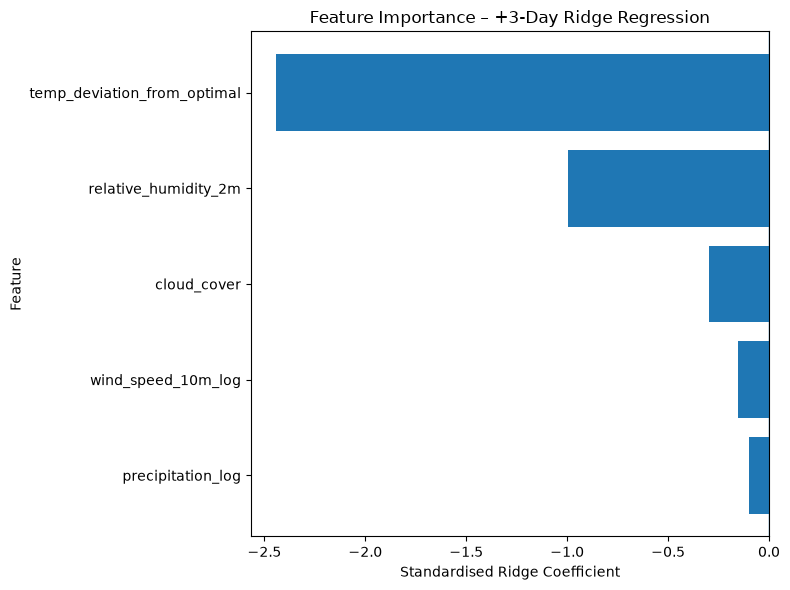

In [106]:
# Plot Ridge coefficient importance
reports_dir = Path("../../reports/comfort_climate")
reports_dir.mkdir(parents=True, exist_ok=True)
plt.figure(figsize=(8, 6))

plt.barh(
    feature_importance["feature"],
    feature_importance["coefficient"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("Standardised Ridge Coefficient")
plt.ylabel("Feature")
plt.title("Feature Importance – +3-Day Ridge Regression")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    reports_dir / "cci_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [107]:
Model_Coefficients_explanations="""
The standardised Ridge coefficients were examined to understand the relative contribution of each selected feature to the predicted Climate Comfort Index (CCI). All five features had negative coefficients, meaning that higher values of these features were associated with lower predicted CCI after accounting for the other features in the model.

The strongest coefficient was **temperature deviation from optimal**, with a coefficient of **-2.445**. This indicates that being further away from the optimal temperature of 22°C was associated with a lower predicted CCI. This is consistent with the CCI formula, where comfort decreases as temperature moves away from the optimum.

**Relative humidity** had the second-largest absolute coefficient (**-0.994**). This indicates a negative relationship between humidity and predicted CCI after controlling for the other selected weather variables. This result is also consistent with the dataset, where humidity observations were predominantly above the 50% optimal level used in the CCI calculation.

**Cloud cover** had a coefficient of **-0.297**, indicating that greater cloud cover was associated with lower predicted CCI. This direction agrees with the CloudScore component of the CCI formula.

**Wind speed (log-transformed)** had a smaller coefficient of **-0.154**, while **precipitation (log-transformed)** had the smallest absolute coefficient at **-0.099**. Both therefore contributed less to the Ridge model's predictions than temperature deviation and humidity within the selected feature set.

Overall, the coefficient results show that temperature deviation and humidity were the strongest contributors among the selected features, while cloud cover, wind speed and precipitation had smaller model coefficients. These coefficients describe the model's learned linear relationships and should not be interpreted as causal effects.
"""

In [108]:
print_tile(size="h3", key='Model_Coefficients_explanations', value=Model_Coefficients_explanations)

### J.6 Residual Analysis

Validation Residual Summary (+3 days):
count    877.000000
mean      -2.809154
std       10.126764
min      -43.426699
25%       -8.721406
50%       -1.370137
75%        4.115860
max       22.754753
Name: cci_target_3d, dtype: float64


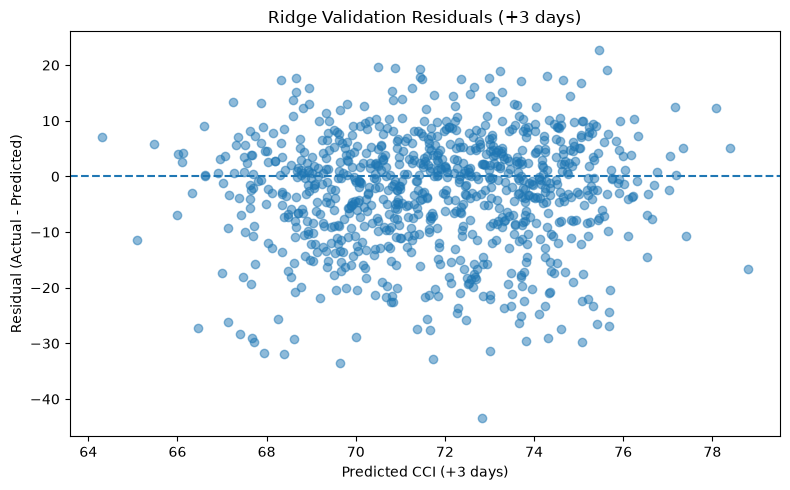

In [109]:
# ------------------------------------------------------------
# J.6 Residual Analysis
# ------------------------------------------------------------

# Use the +3-day validation predictions for representative
# residual analysis.

residuals_3d = y_val_3d - val_preds_3d

# Display summary statistics for the residuals
print("Validation Residual Summary (+3 days):")
print(residuals_3d.describe())

# Plot residuals against predicted CCI values
plt.figure(figsize=(8, 5))
plt.scatter(val_preds_3d, residuals_3d, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted CCI (+3 days)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Ridge Validation Residuals (+3 days)")
plt.tight_layout()
plt.savefig(
    reports_dir / "cci_residual.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [110]:
residual_explanations = """
The validation residuals were analysed using the difference between the actual and predicted CCI values, where residual = actual CCI − predicted CCI. A residual of zero therefore represents a prediction that exactly matches the observed target.

The validation residuals had a mean of -2.809 and a median of -1.370 CCI points. The negative mean indicates a small tendency for the Ridge model to overpredict CCI on average. The residual standard deviation was 10.127 CCI points, showing that prediction errors vary substantially across observations.

The residuals ranged from -43.427 to 22.755 CCI points. This indicates that some individual predictions have considerably larger errors than the typical prediction error, particularly on the overprediction side.

The residual scatter plot shows a horizontal reference line at zero, with most observations distributed around this line. Most predicted CCI values are concentrated approximately between 66 and 76, indicating that the model produces predictions mainly within this central range. The residual plot does not provide sufficient evidence of a strong systematic pattern from the visual inspection alone, although the concentration of predictions suggests that the model may have limited ability to represent the full range of CCI values.

Overall, the residual analysis indicates that the Ridge model has a small average overprediction tendency and some relatively large individual errors. These results provide additional context for the MAE and RMSE metrics and highlight a potential limitation of the linear Ridge model in predicting less typical CCI conditions.
"""

In [111]:
print_tile(size="h3", key='residual_explanations', value=residual_explanations)


### J.7 Final Test Performance

In [112]:
# ------------------------------------------------------------
# J.6 Final Test Performance
# ------------------------------------------------------------

# Generate predictions for the untouched test dataset
test_preds_1d = ridge_pipe_1d.predict(X_test_1d)
test_preds_2d = ridge_pipe_2d.predict(X_test_2d)
test_preds_3d = ridge_pipe_3d.predict(X_test_3d)

# Evaluate final model performance on the test sets
test_metrics_1d = evaluate_regression(
    y_test_1d,
    test_preds_1d,
    "Ridge +1 day - Test"
)

test_metrics_2d = evaluate_regression(
    y_test_2d,
    test_preds_2d,
    "Ridge +2 days - Test"
)

test_metrics_3d = evaluate_regression(
    y_test_3d,
    test_preds_3d,
    "Ridge +3 days - Test"
)

Ridge +1 day - Test -- MAE: 6.405 (primary), RMSE: 8.549
Ridge +2 days - Test -- MAE: 7.300 (primary), RMSE: 9.792
Ridge +3 days - Test -- MAE: 7.816 (primary), RMSE: 10.394


In [113]:
test_performance_explanations="""
The final test set was used only after model development and validation to provide an unbiased estimate of the Ridge model's generalisation performance. The model achieved a test MAE of **7.816 CCI points** and a test RMSE of **10.394 CCI points**.

The test MAE was slightly lower than the validation MAE of **7.975**, indicating that performance remained stable on the unseen test period rather than deteriorating substantially. The RMSE was higher than the MAE, showing that some predictions had larger errors than the typical prediction error.

Overall, the results indicate that the Ridge model provides useful predictive information for the 3-day-ahead Climate Comfort Index and generalises reasonably well to the final unseen period. The test results are retained for final model assessment and are not used for further hyperparameter tuning.
"""

In [114]:
print_tile(size="h2", key='test_performance_explanations', value=test_performance_explanations)

### J.8 Compare predictions against actuals

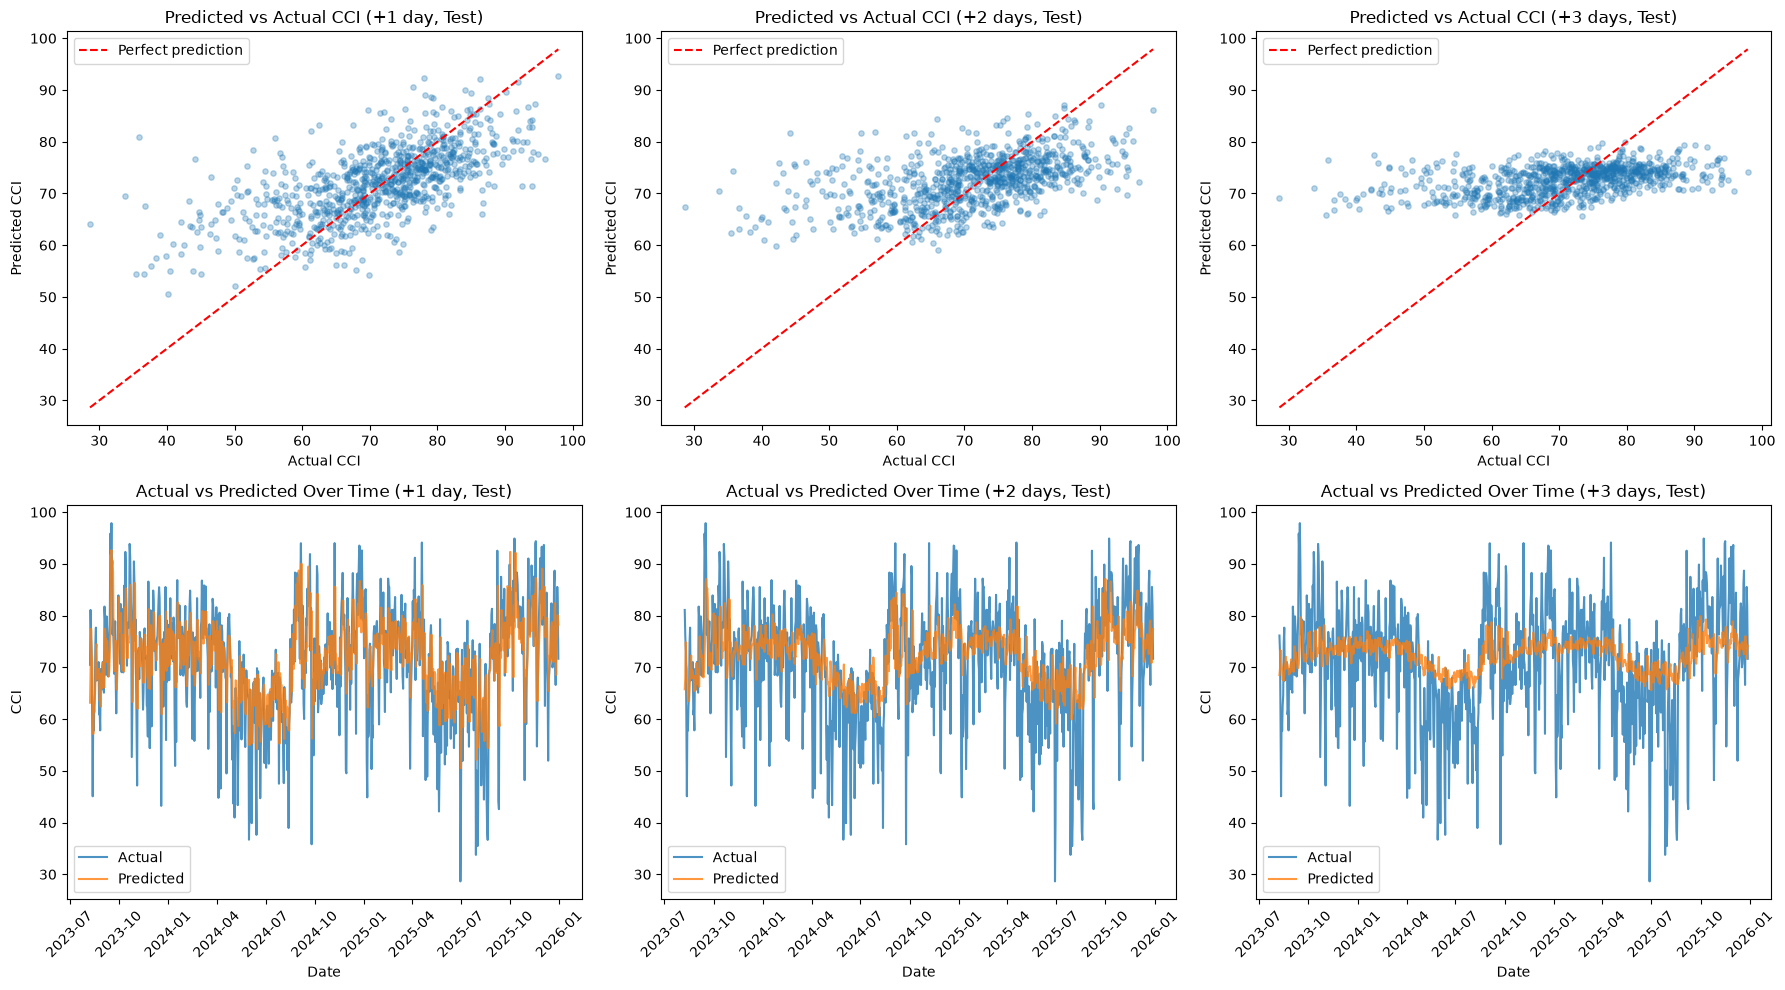

In [115]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

horizons = [
    ("+1 day", y_test_1d, test_preds_1d, test["date"]),
    ("+2 days", y_test_2d, test_preds_2d, test["date"]),
    ("+3 days", y_test_3d, test_preds_3d, test["date"]),
]

for col, (label, y_true, y_pred, dates) in enumerate(horizons):
    # Top row: scatter (predicted vs actual)
    axes[0, col].scatter(y_true, y_pred, alpha=0.3, s=15)
    axes[0, col].plot(
        [y_true.min(), y_true.max()],
        [y_true.min(), y_true.max()],
        color="red", linestyle="--", label="Perfect prediction",
    )
    axes[0, col].set_xlabel("Actual CCI")
    axes[0, col].set_ylabel("Predicted CCI")
    axes[0, col].set_title(f"Predicted vs Actual CCI ({label}, Test)")
    axes[0, col].legend()

    # Bottom row: line chart over time
    axes[1, col].plot(dates.iloc[: len(y_true)], y_true.values, label="Actual", alpha=0.8)
    axes[1, col].plot(dates.iloc[: len(y_pred)], y_pred, label="Predicted", alpha=0.8)
    axes[1, col].set_xlabel("Date")
    axes[1, col].set_ylabel("CCI")
    axes[1, col].set_title(f"Actual vs Predicted Over Time ({label}, Test)")
    axes[1, col].legend()
    axes[1, col].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(
    reports_dir / "cci_predicted_against_actual.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [116]:
prediction_comparison_explanations = """
The scatter and time-series plots reveal a clear, consistent pattern of
degrading discriminative ability as the forecast horizon increases from
+1 to +3 days. At +1 day, predictions track actual CCI reasonably well,
including capturing several sharp dips in the time series. At +2 days,
the scatter widens and the predicted line visibly smooths relative to
actual. At +3 days, the effect is pronounced: predictions compress into
a narrow band (roughly 65-80), regardless of the true value -- even when
actual CCI falls to 30-40 (a "Poor comfort" day per the assignment's
interpretation bands), the model still predicts a "Comfortable"-range
value. The +3-day predicted time series is visibly flattened relative to
the highly variable actual series.

This is consistent with, and directly explains, the RMSE-MAE gap
identified earlier in J.4: as predictive uncertainty grows with horizon,
a model optimising for average error learns that predicting values close
to the historical mean minimises expected loss, at the cost of losing
the ability to anticipate genuine extremes. This is a well-documented
behaviour in multi-step forecasting rather than a flaw specific to this
implementation, but it has a direct, important business implication
(Section J.5): the +3-day CCI prediction should not be relied upon to
flag genuinely extreme comfort conditions (very poor or excellent days),
since the model's systematic tendency is to under-predict how extreme
conditions will actually be at that horizon. The +1-day model is
meaningfully more trustworthy for this purpose than the +3-day model,
which is an important, evidence-based nuance for the API's documentation
and the report's limitations discussion -- the current deployment treats
all three horizons as equally reliable, which this analysis shows is not
accurate.
"""

In [117]:
print_tile(size="h3", key='prediction_comparison_explanations', value=prediction_comparison_explanations)

### J.9 Business Impact from Current Model Performance

In [118]:
business_impacts_explanations = """
The Ridge model achieved a validation MAE of 7.975 CCI points on the 0-100 scale. This means that, on average, the model's 3-day-ahead CCI predictions differ from the actual CCI by approximately 8 points. The validation RMSE of 10.504 is higher than the MAE, indicating that some individual predictions have larger errors than the typical prediction.

For potential business applications such as outdoor event planning, tourism planning, or general outdoor activity decisions, this level of error should be considered when interpreting predictions. The CCI interpretation bands are 20 points wide, so an average error of approximately 8 points is meaningful, particularly when a predicted CCI is close to a boundary between two categories.

For example, a prediction close to the boundary between "Comfortable" (60-79) and "Excellent" (80-100) could result in the actual day being classified in the adjacent category. Similarly, an error around the boundary between "Moderate" (40-59) and "Comfortable" (60-79) could change the practical interpretation of the forecast. These boundary cases should therefore not be treated as completely certain decisions.

The residual analysis also showed that the model has a small tendency to overpredict CCI, with a mean residual of approximately -2.81 points. The validation predictions were concentrated mainly around the 66-76 CCI range. This suggests that users should be cautious when interpreting predictions outside the model's commonly predicted range, particularly because the model may have limited ability to represent the full variation in CCI conditions.

Overall, the current Ridge model provides useful quantitative guidance for typical 3-day-ahead comfort conditions and performs better than the DummyRegressor baseline on the validation set. However, the model should be treated as decision support rather than a guarantee of future conditions. Business users should consider the prediction error and CCI category boundaries when making decisions, particularly for activities where weather conditions have significant consequences.

"""

In [119]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

## H. Project Outcomes

In [120]:
# ------------------------------------------------------------
# H. Project Outcomes
# ------------------------------------------------------------

# Save the three final Ridge model pipelines.
models_dir = Path("../../models/comfort_climate")
models_dir.mkdir(parents=True, exist_ok=True)

dump(ridge_pipe_1d, models_dir / "ridge_pipeline_1d.joblib")
dump(ridge_pipe_2d, models_dir / "ridge_pipeline_2d.joblib")
dump(ridge_pipe_3d, models_dir / "ridge_pipeline_3d.joblib")

print(f"Saved to {models_dir / 'ridge_pipeline_1d.joblib'}")
print(f"Saved to {models_dir / 'ridge_pipeline_2d.joblib'}")
print(f"Saved to {models_dir / 'ridge_pipeline_3d.joblib'}")

experiment_outcome = "Hypothesis Supported"

Saved to ../../models/comfort_climate/ridge_pipeline_1d.joblib
Saved to ../../models/comfort_climate/ridge_pipeline_2d.joblib
Saved to ../../models/comfort_climate/ridge_pipeline_3d.joblib


In [121]:
experiment_outcome = "Hypothesis Confirmed"

In [122]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [123]:
experiment_results_explanations = """
H1 was supported on the validation set: the Ridge Regression model achieved a validation MAE of 7.975 CCI points, compared with 8.486 for the DummyRegressor baseline. This represents an improvement of approximately 6.0% in MAE, demonstrating that the selected weather features provide useful predictive information beyond the feature-free mean baseline. However, final confirmation of generalisation performance will be based on the untouched test set.

Key insights gained during the experiment include:

* Linear correlation alone can understate the usefulness of features with a non-linear relationship to the target. Re-expressing temperature as its absolute deviation from the CCI formula's optimal temperature of 22°C increased the absolute correlation with the 3-day-ahead CCI target from approximately 0.307 for raw temperature to 0.331 for temperature deviation. This supports using domain knowledge to construct features that better represent the structure of the target.

* Not every formula-motivated engineered feature improved the linear relationship with the target. The humidity deviation feature had a correlation of approximately -0.119 with the target, compared with approximately -0.132 for raw humidity. This indicates that the engineered feature did not provide a stronger simple linear relationship in this dataset and demonstrates the importance of evaluating engineered features empirically.

* Several temperature-related features were highly correlated with each other. temperature_2m and temp_deviation_from_optimal had a correlation of approximately -0.908, temperature_2m and temperature_3d_rolling_mean had a correlation of approximately 0.953, and temp_deviation_from_optimal and temperature_3d_rolling_mean had a correlation of approximately -0.891. This highlights the importance of checking feature-to-feature relationships, not only feature-to-target correlations, when preparing predictors for a linear model.

* The Ridge model's validation performance was better than the DummyRegressor baseline, but the improvement was modest. This suggests that the selected weather variables contain useful predictive information while also indicating that the current feature set and linear model do not capture all variation in the 3-day-ahead CCI.

Potential future improvements include:

1. Test a non-linear regression model, such as Random Forest or Gradient Boosting, using the same chronological validation framework. These models may capture non-linear relationships that Ridge cannot represent directly.

2. Add seasonal or cyclical features, such as month represented using sine and cosine transformations, and evaluate whether they provide additional predictive value.

3. Investigate additional weather variables available from Open-Meteo and test them empirically for incremental predictive value rather than adding variables without evidence.

The current Ridge model is therefore a useful and interpretable first machine learning model for the CCI forecasting task. Its validation performance supports H1 and justifies further evaluation. The final model selection and production recommendation should be made after evaluating performance on the untouched test set and comparing the Ridge model with alternative candidate models.

"""

In [124]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)